# Data re-uploading — a universal quantum classifier from a single qubit

**Marcin Płodzień** — Institute of Theoretical Physics, Jagiellonian University in Kraków  
[ORCID 0000-0002-0835-1644](https://orcid.org/0000-0002-0835-1644) · [github.com/MarcinPlodzien](https://github.com/MarcinPlodzien) · [www](https://chaos.if.uj.edu.pl/marcinplodzien/)

*Quantum Many-Body Simulation — Chapter 13 — Quantum machine learning*

## 1. Introduction and motivation

### 1.1 What a classifier does

A classification problem gives $M$ examples $(\mathbf x_\mu,y_\mu)$, $\mu=1,\dots,M$: a point $\mathbf x_\mu\in\mathbb R^d$
of measured numbers and a label $y_\mu$ from a small set of classes $\{0,1,\dots,C-1\}$. A *classifier* is a rule
$\mathbf x\mapsto y$, chosen from a family of rules by adjusting free parameters on the examples (the *training set*),
and judged by the fraction of correct labels on new points (the *test set*). Two properties decide whether a family
of rules is useful: it must contain a rule that reproduces the shape of the true class regions (*expressivity*), and
the training must be able to find that rule from a finite sample.

The classical example is a neural network with one hidden layer. Every hidden neuron receives the whole input,
forms a weighted sum $\mathbf w_i\cdot\mathbf x+b_i$, and passes it through a nonlinear function $\varphi$; the output
is a weighted sum of the $N$ neuron outputs,

$$h(\mathbf x)=\sum_{i=1}^{N}\alpha_i\,\varphi(\mathbf w_i\cdot\mathbf x+b_i). \tag{1}$$

The universal approximation theorem states that functions of the form (1) approximate any continuous function on a
bounded domain to any accuracy, provided $N$ is large enough (Cybenko 1989 for sigmoidal $\varphi$; Hornik 1991 for
any bounded, nonconstant, continuous $\varphi$, as summarised by Pérez-Salinas *et al.*). The input $\mathbf x$ is *copied* into each of the $N$ neurons.

### 1.2 A qubit as a classifier

A qubit can be made into a classifier by writing $\mathbf x$ into the angles of rotation gates, rotating the state
further with trainable gates, and reading out where the final state lies on the Bloch sphere: north hemisphere for
class 0, south hemisphere for class 1. Section 4 shows that a single qubit which receives the data once is a weak
classifier: whatever the trainable rotations do, the boundary between the classes is the intersection of the Bloch
sphere with a plane, and on a circle in the data plane the best such boundary gets only three quarters of the
points right.
A qubit that already carries $\mathbf x$ cannot be copied into several neurons, as Eq. (1) does with $\mathbf x$,
because the no-cloning theorem ([notebook 20](../ch08_quantum_information_protocols/20_quantum_teleportation.ipynb))
forbids copying an unknown quantum state; the classical numbers $\mathbf x$, however, can be written into the
circuit as many times as we like.

Pérez-Salinas, Cervera-Lierta, Gil-Fuster and Latorre (2020) built a classifier on exactly this idea, *data
re-uploading*: the data are uploaded $L$ times, each time combined with a different trainable rotation of the same
qubit, and the label is read from the fidelities of the final state with a set of *label states* that are as
different from each other as possible. Each layer plays the part of one neuron of Eq. (1), with the rotation angle
$\boldsymbol\theta_i+\mathbf w_i\circ\mathbf x$ in place of $\mathbf w_i\cdot\mathbf x+b_i$. The authors trained the
circuit on nine two-, three- and four-dimensional problems, reached test accuracies above $90\,\%$ with one qubit on
all of them, and found that two and four qubits, with and without entangling gates between the layers, raise the
accuracy and reduce the number of layers needed.

### 1.3 Scope of the claims

A single qubit is simulated exactly by multiplying $2\times2$ matrices, and the four-qubit classifier by vectors of 16
amplitudes; nothing in this notebook needs a quantum computer, and nothing in it shows an advantage over classical
classifiers. The interest of the protocol is the minimal resource count: it shows how much a single qubit can
compute when the data enter repeatedly, and it is the simplest model in which the effect of repeated data encoding on
the expressivity of quantum models can be worked out exactly (Section 10).

### 1.4 Road map

* **Section 3** defines the three data sets of the paper used here (a circle, a non-convex boundary, and a
  three-class annulus), the training and test sets and the accuracy.
* **Section 4** builds the encoding layer and shows why one upload followed by any rotation separates the classes
  by a plane through the Bloch sphere; on the circle the best such plane is a strip that gets three quarters of the
  points right.
* **Section 5** builds the re-uploading circuit: the layer $U(\boldsymbol\theta_i+\mathbf w_i\circ\mathbf x)$, the
  $L$-layer circuit, the label states, the fidelity and weighted fidelity costs, prediction and accuracy, each with
  a checkpoint.
* **Section 6** trains the circuit with Adam, compiled with `lax.scan` and `vmap` over random starts.
* **Section 7** measures test accuracy against the number of layers on the three problems, draws the learned class
  regions and compares with the tables of the paper.
* **Section 8** extends the classifier to two and four qubits, with and without CZ gates, and compares, and
  **Section 9** sums up the role of entanglement and the limit that the number of layers sets for any number of
  qubits.
* **Section 10** discusses the expressivity of re-uploading: the analogy with Eq. (1) used by the authors, and the Fourier
  series in the data whose frequencies are limited by the number of uploads; **Section 11** times the simulation.

### What you will learn

*Physics*

* how classical data become rotation angles of a qubit, and why a single encoding gives only a plane cut of the
  Bloch sphere as decision boundary;
* how label states that are maximally far apart on the Bloch sphere turn fidelities into class scores;
* what entangling gates change in a multi-qubit classifier: the reduced state of a qubit becomes mixed, and its
  fidelities with the label states can no longer reach one;
* why $L$ uploads of a Pauli rotation make the output a Fourier series of degree $L$ in the data.

*Numerical methods*

* the fidelity and weighted fidelity cost functions and their minimisation with Adam;
* training and test sets, selection of the best of several random starts by the training cost only, and the
  comparison of measured accuracies with published ones obtained with a different optimiser;
* the discrete Fourier transform as a test of the frequency content of a model.

*Implementation practice*

* one model function for one, two and four qubits, built from `apply_gate` and `rdm`, batched over data points with
  `jax.vmap`;
* whole training runs compiled into one `lax.scan` and batched over random initialisations with `jax.vmap`;
* checkpoints for every piece: unitarity, orthogonality of the label states, a cost that reaches zero on separable
  data, gradients against finite differences, and the reduction of the non-entangled multi-qubit circuit to
  independent single qubits.

### Prerequisites

* [01 — JAX](../ch01_computational_toolbox/01_jax_from_scratch.ipynb): `jit`, `vmap`, `grad`, `lax.scan` and
  explicit random keys;
* [06 — states, observables and entanglement](../ch03_matrix_free_engine/06_states_observables_entanglement.ipynb):
  Bloch vectors, fidelity $\vert\langle\psi\vert\phi\rangle\vert^2$, reduced density matrices and purity;
* [09 — quantum gates and circuits](../ch04_digital_quantum_circuits/09_quantum_gates_and_circuits.ipynb): the
  rotations $R_y,R_z$, their action on the Bloch sphere, `apply_gate` and the CZ gate;
* [40 — parametrized gates and gradients](40_parametrized_gates_and_gradients.ipynb)
  and [41 — optimisers](41_optimizers.ipynb): the variational loop, reverse-mode
  gradients, and the Adam update;
* [45d — quantum kernel methods](45d_quantum_kernel_methods_classification.ipynb)
  uses a quantum circuit as a fixed feature map for a classical classifier; here the circuit itself is trained.

No machine-learning background beyond these notebooks is assumed. Conventions as before: $\vert0\rangle$ is the
$+1$ eigenstate of $Z$ (north pole of the Bloch sphere), $R_a(\vartheta)=e^{-i\vartheta\sigma^a/2}$, qubit $q$ is
tensor axis $q$.

## Configuration

Every notebook of this course starts with the same cell. Choose where to run (`DEVICE`) and the floating-point precision (`PRECISION`): `"double"` = `float64/complex128` (default, recommended for physics), `"single"` = `float32/complex64` (half the memory, faster on consumer GPUs, but watch the round-off). All code below derives its dtypes from `RDTYPE`/`CDTYPE` and its check tolerances from `TOL`, so nothing else needs to change.

In [1]:
# ==============================================================================
# CONFIGURATION  -- adapt to your hardware, then run the notebook top to bottom
# ==============================================================================
DEVICE    = "auto"     # "auto": use a GPU if JAX finds one, else CPU | "cpu" | "gpu"
PRECISION = "double"   # "double": float64/complex128 | "single": float32/complex64

import os
if DEVICE == "cpu":
    os.environ["JAX_PLATFORMS"] = "cpu"          # must be set BEFORE jax is imported

import string
from functools import partial

import math
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax

# Precision is configurable: "double" = float64/complex128 (default; needed for long time evolutions and
# tight validation), "single" = float32/complex64 (half the memory, faster on consumer GPUs).
# In a notebook PRECISION is defined in the Configuration cell; for this module use the env var QE_PRECISION.
PRECISION = globals().get("PRECISION", os.environ.get("QE_PRECISION", "double"))
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
TOL = 1e-10 if PRECISION == "double" else 1e-4                       # tolerance for sanity checks (asserts)
_LETTERS = string.ascii_letters  # the 52 einsum index labels a-z, A-Z

import time
import matplotlib.pyplot as plt

if DEVICE == "gpu" and jax.default_backend() == "cpu":
    print("WARNING: DEVICE='gpu' requested but JAX found no GPU -- running on CPU.")
print(f"JAX {jax.__version__} | backend: {jax.default_backend()} | devices: {jax.devices()}")
print(f"precision: {PRECISION} -> real {RDTYPE.__name__}, complex {CDTYPE.__name__}, check tolerance TOL={TOL:g}")


JAX 0.11.0 | backend: cpu | devices: [CpuDevice(id=0)]
precision: double -> real float64, complex complex128, check tolerance TOL=1e-10


## 2. Engine recap and notebook helpers

From the engine we take the rotations $R_y$, $R_z$, the CZ gate and $Z$, `apply_gate`, the all-zero state, the
reduced density matrix `rdm`, the pure-state fidelity, and the Adam update of notebook 41. The helper cell sets the
plot style and a timer for the sections.

In [2]:
#| code-fold: true
#| code-summary: "Engine recap — the simulator primitives used in this notebook (click to expand)"
# ==============================================================================
# ENGINE RECAP: the functions of quantum_engine.py (SmoQ.jax) used in this notebook.
# Each one is derived, with its mathematics and an independent check, in notebook 08b
# (Chapter 3), 'Building the quantum simulator engine'.
# States are rank-N tensors of shape (2,)*N; every operator acts through ONE einsum.
# ==============================================================================
# ----------------------------------------------------------------------------
# 1. Elementary matrices: Paulis, Clifford generators, rotations
# ----------------------------------------------------------------------------
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
CZ = jnp.diag(jnp.array([1, 1, 1, -1], dtype=CDTYPE))
def ry(theta):
    """Rotation about y:  Ry(theta) = exp(-i theta Y/2) = [[cos, -sin], [sin, cos]](theta/2)  (real matrix)."""
    c, s = jnp.cos(theta / 2), jnp.sin(theta / 2)
    return jnp.array([[c, -s], [s, c]], dtype=CDTYPE)

def rz(theta):
    """Rotation about z:  Rz(theta) = exp(-i theta Z/2) = diag(e^{-i theta/2}, e^{+i theta/2})."""
    e = jnp.exp(-0.5j * theta)
    return jnp.array([[e, 0], [0, jnp.conj(e)]], dtype=CDTYPE)


# ----------------------------------------------------------------------------
# 2. THE core primitive: a k-qubit operator acting on a tensor through ONE einsum
# ----------------------------------------------------------------------------
def apply_gate(psi, U, qubits):
    """Apply a k-qubit operator U to the axes `qubits` of the tensor `psi`.

    MATH
    ----
    One qubit (k=1), target q:
        psi'[s_0,..,a,..,s_{N-1}] = sum_b  U[a,b] psi[s_0,..,b,..,s_{N-1}]
    Two qubits (k=2), targets (q1,q2); the 4x4 matrix is reshaped to U[a1,a2,b1,b2]:
        psi'[.., a1, .., a2, ..] = sum_{b1,b2} U[a1,a2,b1,b2] psi[.., b1, .., b2, ..]
    This IS the action of (1 x .. x U x .. x 1) -- written without ever building it.

    EINSUM TRANSLATION  (generated automatically below)
    ------------------
        N=3, q=1        :  "db,abc->adc"          d = new (output) index of qubit 1
        N=4, q=(1,3)    :  "efbd,abcd->aecf"      e,f = new indices of qubits 1 and 3
    Recipe: label the axes of psi with letters a,b,c,...; give every target qubit a NEW
    letter (the next unused ones); U carries (new letters)+(old letters of the targets); the
    output is psi's labels with the target letters replaced by the new ones.

    IMPLEMENTATION NOTES
    --------------------
    * reshape of U:  (2^k,2^k) -> (2,)*2k.  Row index = (a1..ak), column = (b1..bk), and
      the FIRST qubit in `qubits` is the most significant bit of the small matrix, i.e. it
      corresponds to the LEFT factor of kron(A,B).
    * `qubits` may be any distinct axes in any order: non-neighbouring gates cost the same.
    * U need not be unitary: projectors, Kraus operators and Hamiltonian terms reuse this.
    * psi may be ANY tensor with those axes of size 2: a state (rank N), a density tensor
      (rank 2N: ket axes 0..N-1, bra axes N..2N-1), ...
    COST   O(2^k * 2^N) operations, O(2^N) memory  (dense matrix: O(4^N) both).
    JAX    `qubits` must be static Python ints (they define the einsum string); psi and U are
           traced, so the function can sit inside jit / grad / vmap / scan.
    """
    qubits = tuple(int(q) for q in qubits)
    k, n = len(qubits), psi.ndim
    U = jnp.asarray(U, dtype=psi.dtype).reshape((2,) * (2 * k))     # matrix -> rank-2k tensor
    inp = list(_LETTERS[:n])                                         # labels of psi's axes
    new = _LETTERS[n:n + k]                                          # fresh labels for the outputs
    out = inp.copy()
    for a, q in zip(new, qubits):
        out[q] = a                                                   # target axes get the new labels
    sub = f"{''.join(new)}{''.join(inp[q] for q in qubits)},{''.join(inp)}->{''.join(out)}"
    return jnp.einsum(sub, U, psi)


# ----------------------------------------------------------------------------
# 3. State preparation
# ----------------------------------------------------------------------------
def zero_state(N):
    """|00...0>: a rank-N tensor of zeros with a single 1 at index (0,0,...,0).
    JAX arrays are immutable: `.at[idx].set(v)` returns an updated COPY (functional style)."""
    return jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)


# ----------------------------------------------------------------------------
# 4. Reduced density matrices & observables (matrix-free)
# ----------------------------------------------------------------------------
def rdm(psi, keep):
    """Reduced density matrix of the qubits `keep` from a PURE state:  rho_A = Tr_B |psi><psi|.

    MATH
        rho_A[a, a'] = sum_{b}  psi[a, b] psi^*[a', b]          (a: indices of A, b: of the rest B)
    EINSUM TRANSLATION   N=3, keep=(0,):   "abc,Abc->aA"   with operands psi, psi^*
        * letters of B (b,c) appear in BOTH operands and not in the output  -> summed = traced out
        * the kept axis gets a different letter in the second operand       -> stays open (a and A)
    The full |psi><psi| (4^N numbers) is never formed; cost O(2^N 2^|A|).
    Returns a (2^|A|, 2^|A|) matrix with row/column order following `keep`.
    """
    keep = tuple(int(q) for q in keep)
    n, k = psi.ndim, len(keep)
    a = list(_LETTERS[:n])
    b = a.copy()
    for new, q in zip(_LETTERS[n:n + k], keep):
        b[q] = new
    sub = f"{''.join(a)},{''.join(b)}->{''.join(a[q] for q in keep)}{''.join(b[q] for q in keep)}"
    return jnp.einsum(sub, psi, jnp.conj(psi)).reshape(2 ** k, 2 ** k)


# ----------------------------------------------------------------------------
# 5. State characteristics: entropies, fidelity, negativity
# ----------------------------------------------------------------------------
def fidelity_pure(psi, phi):
    """F = |<psi|phi>|^2 between two pure states."""
    return jnp.abs(jnp.vdot(psi, phi)) ** 2


# ----------------------------------------------------------------------------
# 15. Variational circuits: ansatz, gradients, optimizers
# ----------------------------------------------------------------------------
def adam_init(theta):
    """Adam state: (first moment m, second moment v, step counter t)."""
    return (jnp.zeros_like(theta), jnp.zeros_like(theta), 0)

def adam_update(theta, g, state, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
    """One Adam step (Kingma & Ba):  m <- b1 m + (1-b1) g,  v <- b2 v + (1-b2) g^2,
        theta <- theta - lr * m_hat / (sqrt(v_hat) + eps),   hats = bias-corrected moments.
    Momentum (m) averages noisy gradients (great with SPSA); v gives a per-parameter step size."""
    m, v, t = state
    t = t + 1
    m = b1 * m + (1 - b1) * g
    v = b2 * v + (1 - b2) * g ** 2
    theta = theta - lr * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
    return theta, (m, v, t)


In [3]:
# ==============================================================================
# PLOT STYLE + small helpers
# ==============================================================================
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]   # colour-blind-friendly, fixed order
MARKERS = ["o", "s", "^", "D", "v", "P"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10, "legend.frameon": False})
SECTION_TIMES = {}                     # wall-clock seconds per section, printed in Section 11
_T0 = [time.perf_counter(), None]


def section_timer(name):
    """Close the timing of the previous section and open a new one called `name`."""
    now = time.perf_counter()
    if _T0[1] is not None:
        SECTION_TIMES[_T0[1]] = now - _T0[0]
    _T0[0], _T0[1] = now, name


def max_abs(a):
    """Largest absolute entry of an array, as a Python float."""
    return float(jnp.max(jnp.abs(jnp.asarray(a))))


section_timer("3 data")

## 3. Three classification problems

All points are drawn uniformly from the square $[-1,1]^2$, and the label follows from a fixed geometric rule. We use
three of the problems of the paper, with its definitions:

* **circle** (2 classes): class 1 if $x_1^2+x_2^2<r^2$ with $r=\sqrt{2/\pi}$, class 0 otherwise. The radius makes the
  disc area $\pi r^2=2$ half of the square, so random guessing scores $50\,\%$;
* **non-convex** (2 classes): class 1 above the curve $x_2=-2x_1+\tfrac32\sin(\pi x_1)$, class 0 below it. Neither
  region is convex, and the wiggles of the boundary have to be resolved;
* **annulus** (3 classes): class 0 inside the circle of radius $r_1=\sqrt{0.8-2/\pi}$, class 1 in the ring
  $r_1<\vert\mathbf x\vert<r_2=\sqrt{0.8}$, class 2 outside. The ring area $\pi(r_2^2-r_1^2)=2$ is again half of the
  square; the inner disc covers $12.8\,\%$ and the outer region $37.2\,\%$.

As in the paper, the training set has 200 points and the test set 4000 points, drawn independently. The *accuracy* is
the fraction of test points that receive the correct label. With 4000 test points its statistical uncertainty is
$\sqrt{a(1-a)/4000}\approx0.003$ at $a=0.95$, so differences of one percentage point between models are resolved;
differences caused by the particular 200 training points are larger, and are part of what Section 7 compares.

circle    : C = 2,  class fractions in the test set 0.510, 0.490


non-convex: C = 2,  class fractions in the test set 0.506, 0.494
annulus   : C = 3,  class fractions in the test set 0.120, 0.508, 0.372


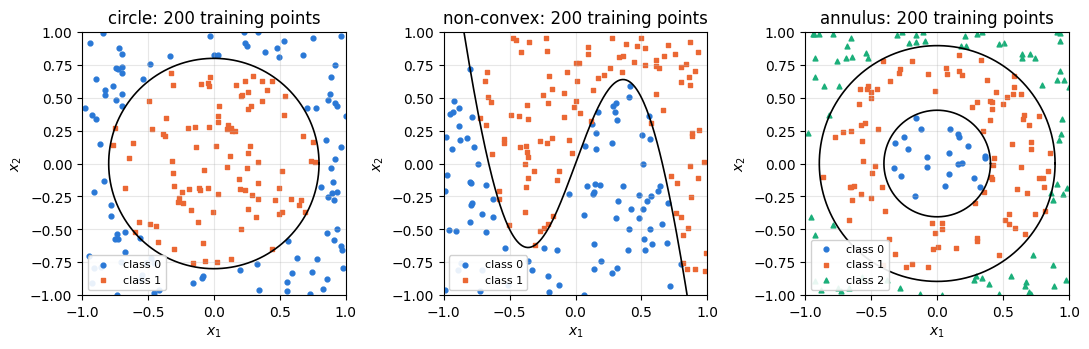

In [4]:
# ==============================================================================
# STEP 1: the data sets
# ==============================================================================
R_CIRCLE = np.sqrt(2 / np.pi)
R_ANN = (np.sqrt(0.8 - 2 / np.pi), np.sqrt(0.8))
PROBLEMS = {"circle": 2, "non-convex": 2, "annulus": 3}          # name -> number of classes C


def labels_of(points, problem):
    """Class labels of the points (shape (M, 2)) for the three problems.

    MATH   circle:     y = 1 if x1^2 + x2^2 < 2/pi
           non-convex: y = 1 if x2 > -2 x1 + 1.5 sin(pi x1)
           annulus:    y = 0, 1, 2 for |x| < r1, r1 < |x| < r2, |x| > r2,  r1^2 = 0.8 - 2/pi, r2^2 = 0.8
    """
    r2 = jnp.sum(points ** 2, axis=1)
    if problem == "circle":
        return (r2 < R_CIRCLE ** 2).astype(jnp.int32)
    if problem == "non-convex":
        return (points[:, 1] > -2 * points[:, 0] + 1.5 * jnp.sin(jnp.pi * points[:, 0])).astype(jnp.int32)
    if problem == "annulus":
        return (r2 > R_ANN[0] ** 2).astype(jnp.int32) + (r2 > R_ANN[1] ** 2).astype(jnp.int32)
    raise ValueError(problem)


def make_data(key, n, problem):
    """n points uniform in [-1, 1]^2 and their labels."""
    pts = jax.random.uniform(key, (n, 2), dtype=RDTYPE, minval=-1.0, maxval=1.0)
    return pts, labels_of(pts, problem)


M_TRAIN, M_TEST = 200, 4000
DATA = {}
for i, problem in enumerate(PROBLEMS):
    k_tr, k_te = jax.random.split(jax.random.PRNGKey(55 + i))
    Xtr, ytr = make_data(k_tr, M_TRAIN, problem)
    Xte, yte = make_data(k_te, M_TEST, problem)
    DATA[problem] = dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, C=PROBLEMS[problem])
    fr = [float(jnp.mean(yte == c)) for c in range(PROBLEMS[problem])]
    print(f"{problem:10s}: C = {PROBLEMS[problem]},  class fractions in the test set "
          + ", ".join(f"{f:.3f}" for f in fr))


def draw_boundaries(ax, problem):
    """Draw the true class boundaries of a problem as black lines."""
    t = np.linspace(0, 2 * np.pi, 300)
    if problem == "circle":
        ax.plot(R_CIRCLE * np.cos(t), R_CIRCLE * np.sin(t), "k-", lw=1.2)
    elif problem == "annulus":
        for r in R_ANN:
            ax.plot(r * np.cos(t), r * np.sin(t), "k-", lw=1.2)
    else:
        u = np.linspace(-1, 1, 300)
        ax.plot(u, -2 * u + 1.5 * np.sin(np.pi * u), "k-", lw=1.2)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (problem, d) in zip(axes, DATA.items()):
    for c in range(d["C"]):
        sel = np.asarray(d["ytr"]) == c
        ax.scatter(np.asarray(d["Xtr"])[sel, 0], np.asarray(d["Xtr"])[sel, 1], s=12, color=PALETTE[c],
                   marker=MARKERS[c], label=f"class {c}")
    draw_boundaries(ax, problem)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(f"{problem}: 200 training points")
    ax.legend(fontsize=8, loc="lower left", frameon=True, framealpha=0.9)
fig.tight_layout()
plt.show()

The measured class fractions agree with the areas computed above to within the sampling fluctuation of 4000 points.
The circle is the easiest shape and the annulus the hardest: its middle class is a ring that surrounds the inner
disc, so a classifier must produce a region with a hole.

In [5]:
section_timer("4 one upload")

## 4. One qubit, one upload

### 4.1 The encoding layer

A general single-qubit rotation needs three angles. We use the Euler form

$$U(\boldsymbol\phi)=R_z(\phi_2)\,R_y(\phi_1)\,R_z(\phi_3),\qquad \boldsymbol\phi=(\phi_1,\phi_2,\phi_3). \tag{2}$$

Multiplying the three matrices $R_z(\vartheta)=\mathrm{diag}(e^{-i\vartheta/2},e^{i\vartheta/2})$ and
$R_y(\vartheta)=\cos\frac\vartheta2\,\mathbb 1-i\sin\frac\vartheta2\,\sigma^y$ gives, with $c=\cos\frac{\phi_1}2$ and
$s=\sin\frac{\phi_1}2$,

$$U(\boldsymbol\phi)=\begin{pmatrix} e^{-i(\phi_2+\phi_3)/2}\,c & -e^{-i(\phi_2-\phi_3)/2}\,s\\
e^{i(\phi_2-\phi_3)/2}\,s & e^{i(\phi_2+\phi_3)/2}\,c\end{pmatrix}, \tag{3}$$

a matrix of determinant $c^2+s^2=1$. Every element of $\mathrm{SU}(2)$ has this form (the Euler decomposition of
notebook 09, Section 3.4), so Eq. (2) is the general rotation of the Bloch sphere. The paper writes the same family in two other conventions. Its Eq. (12),
$e^{i\phi_2\sigma_z}e^{i\phi_1\sigma_y}e^{i\phi_3\sigma_z}$, is our $U(-2\phi_1,-2\phi_2,-2\phi_3)$, and its explicit
matrix, Eq. (29), is our $U(\phi_1,-\phi_3,-\phi_2)$; the authors' published code uses $U(\phi_1,-\phi_2,-\phi_3)$.
All are reparametrisations of the same set of rotations, which the trainable angles and weights absorb.

A two-dimensional data point is uploaded by using its coordinates as angles,
$U(\mathbf x)\equiv U(x_1,x_2,0)$. Acting on $\vert0\rangle$, $R_z(0)$ does nothing, $R_y(x_1)$ tilts the Bloch
vector by the polar angle $x_1$ and $R_z(x_2)$ turns it by the azimuth $x_2$ (notebook 09, Section 3.3). The data
point lands on the Bloch sphere at

$$\mathbf r(\mathbf x)=\big(\sin x_1\cos x_2,\ \sin x_1\sin x_2,\ \cos x_1\big). \tag{4}$$

The cell implements the closed form of Eq. (3) and checks it against the product of the engine rotations of Eq. (2),
unitarity, the determinant, and the Bloch vector of Eq. (4) for the 200 training points of the circle.

In [6]:
# ==============================================================================
# STEP 2: the general rotation U(phi) and the encoding of a data point
# ==============================================================================
def u3(phi):
    """General single-qubit rotation, Eq. (2):  U(phi) = Rz(phi_2) Ry(phi_1) Rz(phi_3).

    MATH            U = [[e^{-i(p2+p3)/2} c, -e^{-i(p2-p3)/2} s], [e^{i(p2-p3)/2} s, e^{i(p2+p3)/2} c]],
                    c = cos(p1/2), s = sin(p1/2)                                          (Eq. (3))
    IMPLEMENTATION  the closed form of Eq. (3): one matrix instead of three matrices and two products, which
                    matters because training evaluates this gate millions of times.  phi is a traced array of
                    length 3, so the gate is differentiable and can sit inside jit / vmap / grad.
    """
    c, s = jnp.cos(phi[0] / 2), jnp.sin(phi[0] / 2)
    ep, em = jnp.exp(-0.5j * (phi[1] + phi[2])), jnp.exp(-0.5j * (phi[1] - phi[2]))
    return jnp.array([[ep * c, -em * s], [jnp.conj(em) * s, jnp.conj(ep) * c]], dtype=CDTYPE)


def u3_euler(phi):
    """Eq. (2) as a product of the engine rotations (independent reference for `u3`)."""
    return rz(phi[1]) @ ry(phi[0]) @ rz(phi[2])


def bloch_vector(psi):
    """Bloch vector (<X>, <Y>, <Z>) of a single-qubit state psi = (a, b).

    MATH   <X> = 2 Re(a^* b),  <Y> = 2 Im(a^* b),  <Z> = |a|^2 - |b|^2
    """
    a, b = psi[0], psi[1]
    return jnp.real(jnp.array([2 * jnp.conj(a) * b, -2j * jnp.conj(a) * b, jnp.abs(a) ** 2 - jnp.abs(b) ** 2]))


def encode(x):
    """One upload of a 2D point: U(x1, x2, 0)|0>."""
    return u3(jnp.array([x[0], x[1], 0.0], dtype=RDTYPE)) @ jnp.array([1.0, 0.0], dtype=CDTYPE)


# CHECKPOINT: Eq. (3) against the product of engine rotations, unitarity and determinant for random angles
phis = np.asarray(jax.random.uniform(jax.random.PRNGKey(1), (50, 3), RDTYPE, -2 * np.pi, 2 * np.pi))
Us = jax.vmap(u3)(jnp.asarray(phis))
err_closed = max_abs(Us - jax.vmap(u3_euler)(jnp.asarray(phis)))
err_unit = max_abs(jnp.einsum("nji,njk->nik", Us.conj(), Us) - jnp.eye(2))
err_det = max_abs(jnp.linalg.det(Us) - 1.0)
print(f"max |Eq. (3) - Rz Ry Rz| = {err_closed:.2e}")
print(f"max |U^dag U - 1|        = {err_unit:.2e}")
print(f"max |det U - 1|          = {err_det:.2e}")
assert err_closed < TOL and err_unit < TOL and err_det < TOL

# CHECKPOINT: Bloch vector of the encoded state, Eq. (4)
pts = DATA["circle"]["Xtr"]
r_num = jax.vmap(lambda x: bloch_vector(encode(x)))(pts)
r_eq4 = jnp.stack([jnp.sin(pts[:, 0]) * jnp.cos(pts[:, 1]), jnp.sin(pts[:, 0]) * jnp.sin(pts[:, 1]),
                   jnp.cos(pts[:, 0])], axis=1)
err_bloch = max_abs(r_num - r_eq4)
print(f"max |r(x) - Eq. (4)|     = {err_bloch:.2e}   (200 training points of the circle)")
assert err_bloch < TOL

max |Eq. (3) - Rz Ry Rz| = 5.27e-16
max |U^dag U - 1|        = 2.22e-16
max |det U - 1|          = 2.23e-16


max |r(x) - Eq. (4)|     = 4.44e-16   (200 training points of the circle)


All errors are at the level of round-off: Eq. (3) equals the product $R_zR_yR_z$, it is unitary with unit
determinant, and the encoded training points sit at the Bloch vectors of Eq. (4). Because $\vert x_1\vert\leq1$,
every point lies within a polar angle of one radian from the north pole, on a cap that covers the azimuths
$-1\leq x_2\leq1$.

### 4.2 A trainable rotation after one upload: a plane through the Bloch sphere

After the upload we may apply any trainable rotation $U(\boldsymbol\phi)$ and measure in the computational basis.
The probability of the outcome 0 is the fidelity with $\vert0\rangle$. A rotation of the state by $U$ is a rotation
$\mathcal R$ of its Bloch vector, so

$$F_0(\mathbf x)=\vert\langle0\vert U(\boldsymbol\phi)\vert\psi(\mathbf x)\rangle\vert^2
=\tfrac12\big(1+\mathbf e_z\cdot\mathcal R\,\mathbf r(\mathbf x)\big)=\tfrac12\big(1+\mathbf m\cdot\mathbf r(\mathbf x)\big),
\qquad \mathbf m=\mathcal R^{\rm T}\mathbf e_z . \tag{5}$$

Here we used the fidelity of two pure states in terms of their Bloch vectors,
$\vert\langle\phi\vert\psi\rangle\vert^2=\mathrm{Tr}(\rho_\phi\rho_\psi)=\frac12(1+\mathbf r_\phi\cdot\mathbf r_\psi)$,
which follows from $\rho=\frac12(\mathbb 1+\mathbf r\cdot\boldsymbol\sigma)$ and
$\mathrm{Tr}(\sigma^a\sigma^b)=2\delta_{ab}$, with $\mathbf r_\phi=\mathbf e_z$ for $\vert0\rangle$. The trainable
rotation only chooses the unit vector $\mathbf m$. If a point is assigned class 0 when $F_0>\lambda$, for some
threshold $\lambda$, the decision boundary is $\mathbf m\cdot\mathbf r(\mathbf x)=2\lambda-1$, so the Bloch sphere is
cut by a plane. This is a *linear* classifier acting on the three features $\mathbf r(\mathbf x)$ of Eq. (4). The
features are nonlinear functions of $\mathbf x$, but they are fixed, and no training of $U(\boldsymbol\phi)$ can
change them.

Because the family of rules is so small, we do not need to train it: we can try all of them. The cell checks
Eq. (5) for a random rotation, then scans 20000 directions $\mathbf m$ spread evenly over the sphere (a Fibonacci
lattice) and, for each, every threshold between consecutive training points, and keeps the plane with the highest
training accuracy. Its test accuracy is the best that one upload can achieve on the circle, up to the choice made on
200 training points.

max |F_0 - (1 + m.r)/2| over the test set = 7.77e-16   (Eq. (5))
best plane: m = (0.029, -0.043, 0.999), threshold 0.8771
training accuracy 82.0 %, test accuracy 74.9 %


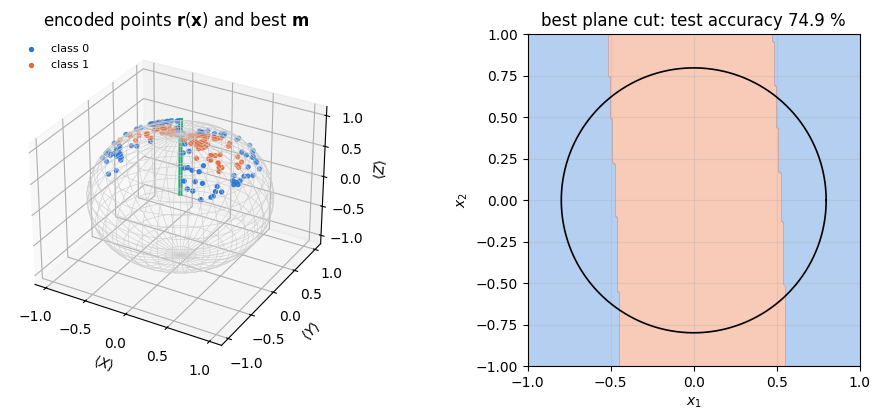

In [7]:
# ==============================================================================
# STEP 3: one upload + one rotation = a plane cut; the best plane for the circle by exhaustive search
# ==============================================================================
def one_upload_p0(phi, x):
    """Probability of outcome 0 after U(phi) U(x)|0>  (Eq. (5))."""
    psi = u3(phi) @ encode(x)
    return jnp.abs(psi[0]) ** 2


d = DATA["circle"]
r_tr = jax.vmap(lambda x: bloch_vector(encode(x)))(d["Xtr"])
r_te = jax.vmap(lambda x: bloch_vector(encode(x)))(d["Xte"])

# CHECKPOINT: Eq. (5) for a random rotation, with m = Bloch vector of U(phi)^dag |0>
phi_r = jax.random.uniform(jax.random.PRNGKey(8), (3,), RDTYPE, 0, 2 * np.pi)
m_r = bloch_vector(u3(phi_r).conj().T @ jnp.array([1.0, 0.0], dtype=CDTYPE))
err_plane = max_abs(jax.vmap(lambda x: one_upload_p0(phi_r, x))(d["Xte"]) - 0.5 * (1 + r_te @ m_r))
print(f"max |F_0 - (1 + m.r)/2| over the test set = {err_plane:.2e}   (Eq. (5))")
assert err_plane < TOL


def best_plane(r, y, n_dir=20000):
    """Plane m.r > t (-> class 1) with the highest accuracy on (r, y), over n_dir directions and all thresholds.

    IMPLEMENTATION  for each direction sort the projections; predicting class 1 above the k-th smallest projection
                    is correct for the class-0 points among the k smallest and the class-1 points among the others,
                    so cumulative sums give the accuracy of every threshold at once.
    """
    i = np.arange(n_dir) + 0.5
    th, ph = np.arccos(1 - 2 * i / n_dir), np.pi * (1 + np.sqrt(5)) * i                  # Fibonacci lattice
    Mdir = np.stack([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)], axis=1)
    P = np.asarray(r) @ Mdir.T                                                           # (M, n_dir)
    order = np.argsort(P, axis=0)
    ys = np.asarray(y)[order]
    n0 = np.vstack([np.zeros(n_dir), np.cumsum(1 - ys, axis=0)])                         # class 0 below threshold
    n1 = np.vstack([np.zeros(n_dir), np.cumsum(ys, axis=0)])
    acc = (n0 + (n1[-1] - n1)) / len(ys)
    k, j = np.unravel_index(np.argmax(acc), acc.shape)
    Ps = np.sort(P[:, j])
    t = Ps[0] - 1 if k == 0 else (Ps[-1] + 1 if k == len(ys) else 0.5 * (Ps[k - 1] + Ps[k]))
    return Mdir[j], t, acc[k, j]


m_best, t_best, acc_plane_tr = best_plane(r_tr, d["ytr"])
acc_plane_te = float(np.mean((np.asarray(r_te) @ m_best > t_best).astype(int) == np.asarray(d["yte"])))
print(f"best plane: m = ({m_best[0]:.3f}, {m_best[1]:.3f}, {m_best[2]:.3f}), threshold {t_best:.4f}")
print(f"training accuracy {100 * acc_plane_tr:.1f} %, test accuracy {100 * acc_plane_te:.1f} %")

fig = plt.figure(figsize=(10, 4.3))
ax = fig.add_subplot(1, 2, 1, projection="3d")
rt = np.asarray(r_tr)
for c in range(2):
    sel = np.asarray(d["ytr"]) == c
    ax.scatter(rt[sel, 0], rt[sel, 1], rt[sel, 2], s=8, color=PALETTE[c], label=f"class {c}")
u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 40), np.linspace(0, np.pi, 20))
ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="0.8", lw=0.4)
ax.quiver(0, 0, 0, *(1.3 * m_best), color=PALETTE[2], lw=3)
ax.set_xlabel(r"$\langle X\rangle$")
ax.set_ylabel(r"$\langle Y\rangle$")
ax.set_zlabel(r"$\langle Z\rangle$")
ax.set_title(r"encoded points $\mathbf{r}(\mathbf{x})$ and best $\mathbf{m}$")
ax.legend(fontsize=8, loc="upper left")
ax2 = fig.add_subplot(1, 2, 2)
g = np.linspace(-1, 1, 151)
G = jnp.asarray(np.stack(np.meshgrid(g, g), -1).reshape(-1, 2))
rg = np.asarray(jax.vmap(lambda x: bloch_vector(encode(x)))(G))
ax2.contourf(g, g, (rg @ m_best > t_best).astype(float).reshape(151, 151), levels=[-0.5, 0.5, 1.5],
             colors=[PALETTE[0], PALETTE[1]], alpha=0.35)
draw_boundaries(ax2, "circle")
ax2.set_xlabel("$x_1$")
ax2.set_ylabel("$x_2$")
ax2.set_title(f"best plane cut: test accuracy {100 * acc_plane_te:.1f} %")
fig.tight_layout()
plt.show()

The best plane points almost exactly along $\mathbf e_z$. A plane $\mathbf m\cdot\mathbf r=t$ with
$\mathbf m\approx\mathbf e_z$ thresholds $\langle Z\rangle=\cos x_1$, so in the data plane it is the vertical strip
$\vert x_1\vert<a$: points near the vertical axis are called "inside", whatever their $x_2$. This is the best that
one upload can do on the circle. The strip misclassifies the parts of the strip above and below the disc and the two
caps of the disc outside the strip, and gets about three quarters of the test points right (the exact optimum of
such strips, $75.8\,\%$, is computed in Section 9). The best plane on the training set reaches $82.0\,\%$ there and
$74.9\,\%$ on the test set; the difference comes from choosing one of many planes on only 200 points, which fits
their particular arrangement.

The azimuth carries $x_2$, but a plane cannot combine "small $x_1$" and "small $x_2$" into "small $x_1^2+x_2^2$".
More trainable rotations after the single upload do not help, since their product is again one rotation.

For one layer on this problem the paper reports a success rate of $0.50$, and the caption of its Fig. 6 describes
dividing the plane in half as the best that the classifier can do; the strip found here shows that one layer can do
better. Section 7 trains the one-layer classifier and compares.

In [8]:
section_timer("5 re-uploading circuit")

## 5. The re-uploading classifier

### 5.1 Uploading the data again

The data can be uploaded a second time after the trainable rotation, followed by a second trainable rotation, and so
on. The state after $L$ such layers is

$$\vert\psi(\mathbf x)\rangle=U(\boldsymbol\phi_L)U(\mathbf x)\cdots U(\boldsymbol\phi_2)U(\mathbf x)\,U(\boldsymbol\phi_1)U(\mathbf x)\vert0\rangle . \tag{6}$$

The rotations no longer combine into one, because $U(\mathbf x)$ sits between them, and the final state is a
nonlinear function of $\mathbf x$ that becomes richer with every layer. The paper merges upload and processing into
one gate per layer and gives each upload its own weights,

$$L(i)=U\big(\boldsymbol\theta_i+\mathbf w_i\circ\mathbf x\big),\qquad
\mathbf w_i\circ\mathbf x=(w_{i1}x_1,\ w_{i2}x_2,\ w_{i3}x_3), \tag{7}$$

where $\circ$ is the elementwise (Hadamard) product and missing components of $\mathbf x$ are set to zero (paper,
Eq. (5)). For two-dimensional data $x_1$ enters the polar rotation $R_y$ and $x_2$ the outer $R_z$, so each layer has
$3+d=5$ parameters. The classifier is

$$\vert\psi(\mathbf x)\rangle=L(L)\cdots L(2)\,L(1)\,\vert0\rangle . \tag{8}$$

Figure 1 shows both versions. The compressed layer of Eq. (7) is not the same gate as $U(\boldsymbol\phi_i)U(\mathbf x)$:
it is a different model with half the depth, and the one used in all experiments of the paper and of this notebook.

![Two circuits for one qubit: (a) L layers, each a data upload U(x) followed by a trainable rotation U(phi_i); (b) L compressed layers U(theta_i + w_i o x); the final state is compared with the label states by the fidelities F_c](figures/reuploading_single_qubit.svg)\
**Figure 1.** The single-qubit classifier with data re-uploading. (a) Each layer uploads the data point with
$U(\mathbf x)$ and processes it with a trainable rotation $U(\boldsymbol\phi_i)$. (b) The compressed layers of Eq. (7)
put data and parameters into one rotation; the weights $\mathbf w_i$ rescale the data in each layer. The output is
the set of fidelities $F_c$ of the final state with the label states (Section 5.3).

**The analogy with a neural network.** Comparing Eq. (7) with Eq. (1), the weights $\mathbf w_i$ play the part of the
neuron weights, the angles $\boldsymbol\theta_i$ that of the biases $b_i$, and the number of layers $L$ that of the
number of hidden neurons; the nonlinear activation is replaced by the trigonometric functions of Eq. (3). The
difference is that the neurons of Eq. (1) act in parallel and their outputs are summed, while the layers of Eq. (8)
act one after another on the same qubit. Section 10 returns to what this analogy does and does not prove.

### 5.2 The circuit in code

The code below is written once for $Q$ qubits, because Section 8 needs it; for now $Q=1$. The parameters of all
layers are stored in arrays `theta` of shape $(Q,L,3)$ and `w` of shape $(Q,L,d)$. For a data point `x` the angles of
layer $l$ on qubit $q$ are `theta[q, l] + w[q, l] * x`, padded with zeros to three components, and the gate is
applied with `apply_gate(psi, u3(phi), [q])`.

The loop over the layers is a `lax.scan` (notebook 01): the body is traced once, whatever $L$ is, which keeps the
compilation time short when we train dozens of classifiers with different $L$. The loop over the qubits is a Python
loop, because qubit indices must be static. The CZ gates of Section 8 need one more idea inside the scan, where the
layer index $l$ is a traced number and cannot select gates by a Python `if`. A CZ gate is diagonal in the
computational basis, and so is any product of CZ gates: applying the CZ gates that follow layer $l$ multiplies every
amplitude $\psi_{s_0\dots s_{Q-1}}$ by a sign $\pm1$. We compute the two sign patterns (after odd and after even
layers) once, by applying the CZ gates with `apply_gate` to a tensor of ones, and inside the scan we multiply the
state by the pattern of the current layer, or by 1 after the last layer. Section 8.1 explains the placement of the
gates; here they are switched off.

Two checks: for $Q=1$ the circuit must equal the product of $L$ matrices $R_z R_y R_z$ built from the engine
rotations; and the state must stay normalised.

In [9]:
# ==============================================================================
# STEP 4: the L-layer re-uploading circuit (Q qubits; CZ entanglers optional, Section 8)
# ==============================================================================
CZ_PAIRS = {1: ([], []), 2: ([(0, 1)], [(0, 1)]), 4: ([(0, 1), (2, 3)], [(1, 2), (0, 3)])}   # after odd / even layers


def layer_angles(theta_ql, w_ql, x):
    """Angles of one compressed layer, Eq. (7):  phi = theta + w o x  (x padded with zeros to 3 components)."""
    d = x.shape[0]
    return theta_ql + jnp.concatenate([w_ql * x, jnp.zeros(3 - d, dtype=x.dtype)])


def cz_signs(Q):
    """Sign patterns of the CZ gates after odd and after even layers, shape (2,) + (2,)*Q.

    MATH            CZ = diag(1, 1, 1, -1) is diagonal, so a product of CZ gates acts on psi[s_0..s_{Q-1}] as a
                    multiplication by sign[s_0..s_{Q-1}] = +-1
    IMPLEMENTATION  apply the CZ gates with apply_gate to a tensor of ones: the result IS the diagonal
    """
    pats = []
    for pairs in CZ_PAIRS[Q]:
        t = jnp.ones((2,) * Q, dtype=CDTYPE)
        for pair in pairs:
            t = apply_gate(t, CZ, list(pair))
        pats.append(t)
    return jnp.stack(pats)


def classifier_state(theta, w, x, entangle=False):
    """Final state of the re-uploading classifier, Eq. (8), on Q qubits.

    MATH            |psi(x)> = R_L E_{L-1} R_{L-1} ... E_1 R_1 |0...0>,
                    R_l = prod_q U(theta[q,l] + w[q,l] o x) on qubit q,
                    E_l = CZ gates on the pairs CZ_PAIRS[Q][(l-1) % 2] (identity if entangle=False); no E after R_L
    IMPLEMENTATION  state = rank-Q tensor; rotations by apply_gate; layers in a lax.scan over (theta[:, l], w[:, l], l);
                    the CZ gates as a multiplication by the sign pattern of cz_signs (identity after the last layer)
    COST            O(L Q 2^Q) per data point
    """
    Q, L = theta.shape[0], theta.shape[1]
    signs = cz_signs(Q)

    def layer(psi, inp):
        th_l, w_l, l = inp
        for q in range(Q):
            psi = apply_gate(psi, u3(layer_angles(th_l[q], w_l[q], x)), [q])
        if entangle:
            psi = psi * jnp.where(l < L - 1, signs[l % 2], 1.0)
        return psi, None
    psi, _ = lax.scan(layer, zero_state(Q), (jnp.swapaxes(theta, 0, 1), jnp.swapaxes(w, 0, 1), jnp.arange(L)))
    return psi


# CHECKPOINT: Q = 1 against the product of the engine rotations Rz Ry Rz, layer by layer
L_chk = 5
k1, k2 = jax.random.split(jax.random.PRNGKey(3))
theta_chk = jax.random.uniform(k1, (1, L_chk, 3), RDTYPE, 0, 2 * np.pi)
w_chk = jax.random.normal(k2, (1, L_chk, 2), RDTYPE)
x_chk = DATA["annulus"]["Xtr"][0]
psi_ref = np.array([1.0, 0.0], dtype=complex)
for l in range(L_chk):
    phi = np.asarray(theta_chk[0, l]) + np.array([*(np.asarray(w_chk[0, l]) * np.asarray(x_chk)), 0.0])
    psi_ref = np.asarray(u3_euler(jnp.asarray(phi))) @ psi_ref
psi_num = classifier_state(theta_chk, w_chk, x_chk)
err_circ = max_abs(psi_num - psi_ref)
err_norm = abs(float(jnp.sum(jnp.abs(psi_num) ** 2)) - 1.0)
print(f"L = {L_chk}: max |psi - product of Rz Ry Rz matrices| = {err_circ:.2e},  | <psi|psi> - 1 | = {err_norm:.2e}")
assert err_circ < TOL and err_norm < TOL

L = 5: max |psi - product of Rz Ry Rz matrices| = 2.48e-16,  | <psi|psi> - 1 | = 0.00e+00


The scanned circuit reproduces the explicit product of five rotations to round-off and keeps the norm.

### 5.3 Label states

The output of the classifier is a state, and a class has to be read from it. The paper assigns to every class $c$ a
*label state* $\vert\tilde\psi_c\rangle$ and chooses the label states as far apart from each other as possible on the
Bloch sphere (*maximal orthogonality*). By the fidelity formula of Section 4.2, the overlap of two label states with
Bloch vectors $\mathbf n_c$, $\mathbf n_{c'}$ is $\vert\langle\tilde\psi_c\vert\tilde\psi_{c'}\rangle\vert^2=\frac12(1+\mathbf n_c\cdot\mathbf n_{c'})$,
so we need $C$ unit vectors with the smallest possible mutual scalar products:

| $C$ | Bloch vectors $\mathbf n_c$ | $\mathbf n_c\cdot\mathbf n_{c'}$ | overlap $\frac12(1+\mathbf n_c\cdot\mathbf n_{c'})$ |
|---|---|---|---|
| 2 | north and south pole: $\vert0\rangle$, $\vert1\rangle$ | $-1$ | $0$ |
| 3 | three directions $120^\circ$ apart on a great circle | $-\frac12$ | $\frac14$ |
| 4 | vertices of a regular tetrahedron | $-\frac13$ | $\frac13$ |

For three classes we put the great circle in the $x$–$z$ plane with one vector at the north pole; for four classes
one vertex of the tetrahedron is at the north pole and the other three at polar angle $\arccos(-\frac13)$ and
azimuths $0,\pm\frac{2\pi}3$. Both orientations follow the authors' published code (Pérez-Salinas,
`universal_qlassifier` on GitHub, cited in the paper as its Ref. [24]); the paper's Fig. 3 shows the tetrahedron. A Bloch vector with polar angle $\vartheta$ and azimuth $\varphi$
belongs to the state $\cos\frac\vartheta2\vert0\rangle+e^{i\varphi}\sin\frac\vartheta2\vert1\rangle$. With $C$ label
states, the expected fidelities of a perfectly classified point of class $s$ form the vector

$$Y_c(s)=\vert\langle\tilde\psi_c\vert\tilde\psi_s\rangle\vert^2 = 1\ \text{for}\ c=s,\qquad
0,\ \tfrac14,\ \tfrac13\ \text{for}\ c\neq s\ \text{and}\ C=2,3,4, \tag{9}$$

which enters the weighted cost of Section 5.4. The paper quotes $Y_r=\frac13$ for the tetrahedron.

In [10]:
# ==============================================================================
# STEP 5: label states and the target fidelities Y_c(s)
# ==============================================================================
def state_from_bloch(theta_b, phi_b):
    """cos(theta/2)|0> + e^{i phi} sin(theta/2)|1>: the pure state with polar angle theta and azimuth phi."""
    return jnp.array([jnp.cos(theta_b / 2), jnp.exp(1j * phi_b) * jnp.sin(theta_b / 2)], dtype=CDTYPE)


def label_states(C):
    """Maximally orthogonal single-qubit label states for C = 2, 3, 4 classes (rows of a (C, 2) array)."""
    if C == 2:
        angles = [(0.0, 0.0), (np.pi, 0.0)]
    elif C == 3:
        angles = [(0.0, 0.0), (2 * np.pi / 3, 0.0), (2 * np.pi / 3, np.pi)]          # x-z great circle
    elif C == 4:
        t = np.arccos(-1 / 3)
        angles = [(0.0, 0.0), (t, 0.0), (t, 2 * np.pi / 3), (t, -2 * np.pi / 3)]   # tetrahedron
    else:
        raise ValueError("C must be 2, 3 or 4")
    return jnp.stack([state_from_bloch(a, b) for a, b in angles])


def target_fidelities(C):
    """Matrix Y[s, c] = |<psi_c|psi_s>|^2 of Eq. (9): row s = expected fidelities of a point of class s."""
    S = label_states(C)
    return jnp.abs(S.conj() @ S.T) ** 2


# CHECKPOINT: normalisation and the overlaps of the table
for C, off in [(2, 0.0), (3, 0.25), (4, 1 / 3)]:
    Yc = target_fidelities(C)
    expect = off * jnp.ones((C, C)) + (1 - off) * jnp.eye(C)
    err_lab = max_abs(Yc - expect)
    print(f"C = {C}: overlaps |<psi_c|psi_c'>|^2 for c != c' = {float(Yc[0, 1]):.6f}, max error vs table = {err_lab:.2e}")
    assert err_lab < TOL

C = 2: overlaps |<psi_c|psi_c'>|^2 for c != c' = 0.000000, max error vs table = 3.75e-33


C = 3: overlaps |<psi_c|psi_c'>|^2 for c != c' = 0.250000, max error vs table = 2.22e-16


C = 4: overlaps |<psi_c|psi_c'>|^2 for c != c' = 0.333333, max error vs table = 1.67e-16


The label states have the overlaps of the table. A point is assigned the class whose label state has the
largest fidelity with the final state; for $C=2$ this is the hemisphere rule of Section 4.2.

### 5.4 Two cost functions

Training needs a single number that measures how wrong the classifier is on the training set. The paper uses two.
The **fidelity cost** (paper, Eq. (7)) pulls every final state towards the label state of its class $s_\mu$:

$$\chi^2_{\rm f}=\frac1M\sum_{\mu=1}^{M}\Big(1-\big\vert\langle\tilde\psi_{s_\mu}\vert\psi(\mathbf x_\mu)\rangle\big\vert^2\Big). \tag{10}$$

The **weighted fidelity cost** (paper, Eq. (9)) uses the fidelities with *all* label states,
$F_c(\mathbf x)=\vert\langle\tilde\psi_c\vert\psi(\mathbf x)\rangle\vert^2$, multiplies them by trainable class
weights $\alpha_c$, and compares them with the expected fidelities $Y_c(s_\mu)$ of Eq. (9):

$$\chi^2_{\rm wf}=\frac1{2M}\sum_{\mu=1}^{M}\sum_{c=1}^{C}\Big(\alpha_c F_c(\mathbf x_\mu)-Y_c(s_\mu)\Big)^2 . \tag{11}$$

We divide both sums by $M$, as the authors' code does and the printed equations do not; this changes the value but
not the minimiser. The fidelity cost
only pulls a state towards its own label state; the weighted cost also pushes it away from the others, to the
overlaps they would have with the correct label state, and the weights $\alpha_c$ let the classifier rescale the
fidelity of each class. It has $C$ more parameters. A point is predicted to be in the class with the largest
score,

$$\hat y(\mathbf x)=\arg\max_c F_c(\mathbf x)\ \ \text{for}\ \chi^2_{\rm f},\qquad
\hat y(\mathbf x)=\arg\max_c \alpha_cF_c(\mathbf x)\ \ \text{for}\ \chi^2_{\rm wf}, \tag{12}$$

the second form being the choice consistent with Eq. (11), where $\alpha_sF_s$ is driven to 1 and $\alpha_rF_r$ to
values below 1. The paper's text does not state this rule; it follows the authors' published code
(`universal_qlassifier`, see the references). The single-qubit classifier with $\chi^2_{\rm wf}$ has $(3+d)L+C$ parameters, for example 12 for
$L=2$ on the circle, the number the paper quotes.

In code all trainable numbers are stored in one flat vector, which is what the engine's `adam_update` expects;
`unpack` cuts it into `theta`, `w` and `alpha`. The fidelities for several qubits (Section 8) are computed from the
one-qubit reduced density matrices, $F_{c,q}=\langle\tilde\psi_c\vert\rho_q\vert\tilde\psi_c\rangle$; for $Q=1$
this is $\vert\langle\tilde\psi_c\vert\psi\rangle\vert^2$.

In [11]:
# ==============================================================================
# STEP 6: parameters, fidelities, the two costs, prediction and accuracy
# ==============================================================================
def n_params(Q, L, d, C):
    """Length of the flat parameter vector: theta (Q,L,3), w (Q,L,d), alpha (C,Q)."""
    return Q * L * (3 + d) + C * Q


def unpack(p, Q, L, d, C):
    """Flat vector -> theta (Q,L,3), w (Q,L,d), alpha (C,Q)."""
    n1, n2 = Q * L * 3, Q * L * d
    return p[:n1].reshape(Q, L, 3), p[n1:n1 + n2].reshape(Q, L, d), p[n1 + n2:].reshape(C, Q)


def fidelities(p, pts, cfg):
    """F[mu, c, q] = <psi_c| rho_q(x_mu) |psi_c> for all points (vmap over the data).

    MATH   rho_q = Tr_{other qubits} |psi(x)><psi(x)|;  for Q = 1, F = |<psi_c|psi(x)>|^2
    """
    Q, L, d, C, ent = cfg
    theta, w, _ = unpack(p, Q, L, d, C)
    S = label_states(C)

    def one(x):
        psi = classifier_state(theta, w, x, ent)
        rhos = jnp.stack([rdm(psi, [q]) for q in range(Q)])                   # (Q, 2, 2)
        return jnp.real(jnp.einsum("ca,qab,cb->cq", S.conj(), rhos, S))
    return jax.vmap(one)(pts)


def scores(p, pts, cfg, cost):
    """Class scores of Eq. (12): F_c (summed over qubits) or the weighted fidelities sum_q alpha_cq F_cq."""
    Q, L, d, C, ent = cfg
    F = fidelities(p, pts, cfg)
    if cost == "f":
        return jnp.sum(F, axis=2)
    return jnp.einsum("mcq,cq->mc", F, unpack(p, Q, L, d, C)[2])


def chi2_f(p, pts, y, cfg):
    """Fidelity cost, Eq. (10): mean over points of 1 - F_{s_mu}.  Used with Q = 1 only (for Q > 1 this average of
    one-qubit fidelities is not the paper's multi-qubit fidelity cost, which uses computational-basis label states)."""
    F = jnp.mean(fidelities(p, pts, cfg), axis=2)                               # (M, C)
    return jnp.mean(1.0 - jnp.take_along_axis(F, y[:, None], axis=1)[:, 0])


def chi2_wf(p, pts, y, cfg):
    """Weighted fidelity cost, Eq. (11) (Eq. (16) for Q > 1):  (1/2M) sum_mu sum_c (sum_q alpha_cq F_cq - Y_c(s_mu))^2."""
    Y = target_fidelities(cfg[3])[y]                                            # (M, C)
    return 0.5 * jnp.mean(jnp.sum((scores(p, pts, cfg, "wf") - Y) ** 2, axis=1))


COSTS = {"f": chi2_f, "wf": chi2_wf}


scores_jit = jax.jit(scores, static_argnames=("cfg", "cost"))      # compiled once per configuration


def predict(p, pts, cfg, cost):
    """Predicted classes, Eq. (12)."""
    return jnp.argmax(scores_jit(p, pts, cfg=cfg, cost=cost), axis=1)


def accuracy(p, pts, y, cfg, cost):
    """Fraction of points whose predicted class, Eq. (12), equals the label."""
    return float(jnp.mean(predict(p, pts, cfg, cost) == y))


def init_params(key, n_starts, Q, L, d, C):
    """Random starts: theta ~ U[0, 2 pi), w ~ N(0, 1), alpha = 1.  Returns (n_starts, n_params)."""
    k1, k2 = jax.random.split(key)
    th = jax.random.uniform(k1, (n_starts, Q * L * 3), RDTYPE, 0, 2 * np.pi)
    w = jax.random.normal(k2, (n_starts, Q * L * d), RDTYPE)
    return jnp.concatenate([th, w, jnp.ones((n_starts, C * Q), RDTYPE)], axis=1)


# CHECKPOINT 1: on a trivially separable set the fidelity cost reaches zero at known parameters.
# Class 0 at x1 = -1/2, class 1 at x1 = +1/2 (x2 arbitrary).  With L = 1, theta_1 = pi/2, w_1 = pi the polar angle is
# phi_1 = pi/2 + pi x1 = 0 or pi: the state is exactly |0> or |1>, whatever x2 does to the azimuth.
key_x2 = jax.random.uniform(jax.random.PRNGKey(4), (40,), RDTYPE, -1, 1)
pts_sep = jnp.stack([jnp.where(jnp.arange(40) < 20, -0.5, 0.5), key_x2], axis=1)
y_sep = (jnp.arange(40) >= 20).astype(jnp.int32)
cfg_sep = (1, 1, 2, 2, False)
p_exact = jnp.array([np.pi / 2, 0.0, 0.0, np.pi, 0.3, 1.0, 1.0], dtype=RDTYPE)       # theta (1,1,3), w (1,1,2), alpha
c_exact = float(chi2_f(p_exact, pts_sep, y_sep, cfg_sep))
print(f"separable set: chi2_f at the exact solution = {c_exact:.2e},  accuracy = {accuracy(p_exact, pts_sep, y_sep, cfg_sep, 'f'):.3f}")
assert c_exact < TOL

# CHECKPOINT 2: reverse-mode gradient against central finite differences, both costs, L = 3 on the annulus
cfg_chk = (1, 3, 2, 3, False)
p_chk = init_params(jax.random.PRNGKey(5), 1, *cfg_chk[:4])[0]
d = DATA["annulus"]
for name, fn0 in COSTS.items():
    fn = jax.jit(fn0, static_argnames=("cfg",))
    g_ad = jax.grad(fn0)(p_chk, d["Xtr"], d["ytr"], cfg_chk)
    h = 1e-5 if PRECISION == "double" else 1e-2
    eye = jnp.eye(p_chk.size, dtype=RDTYPE)
    g_fd = jnp.array([(fn(p_chk + h * e, d["Xtr"], d["ytr"], cfg=cfg_chk) - fn(p_chk - h * e, d["Xtr"], d["ytr"], cfg=cfg_chk)) / (2 * h)
                      for e in eye])
    rel = max_abs(g_ad - g_fd) / max_abs(g_ad)
    print(f"chi2_{name:2s}: {p_chk.size} parameters, max |grad_AD - grad_FD| / max |grad| = {rel:.2e}")
    assert rel < (1e-7 if PRECISION == "double" else 1e-2)

separable set: chi2_f at the exact solution = 3.61e-17,  accuracy = 1.000


chi2_f : 18 parameters, max |grad_AD - grad_FD| / max |grad| = 8.42e-11


chi2_wf: 18 parameters, max |grad_AD - grad_FD| / max |grad| = 3.26e-11


On the separable set the fidelity cost is zero to round-off at the predicted parameters, and every point is
classified correctly: the data rotate the polar angle onto exactly $0$ or $\pi$. The gradients from `jax.grad`
agree with central finite differences to the truncation error $O(h^2)\approx10^{-10}$ of the difference quotient.

In [12]:
section_timer("6 training")

## 6. Training

### 6.1 Optimiser and protocol

The paper minimises the costs with L-BFGS-B, the limited-memory quasi-Newton method of Byrd *et al.* (1995) from
SciPy, with its default settings. We use Adam (notebook 41, Eq. (10) there) with the exact gradient from `jax.grad`, for two reasons: the whole training run can then be compiled into one
`lax.scan` and batched over random starts with `vmap`, and Adam with a fixed number of steps has a cost that is known
in advance, which keeps the notebook within its time budget. The price is that Adam with a few hundred steps does not
converge to a local minimum as tightly as a quasi-Newton method run to its stopping criterion; Section 7 compares the
outcomes.

The protocol for every classifier is:

1. draw $K$ random starts: $\boldsymbol\theta$ uniform in $[0,2\pi)$, $\mathbf w$ standard normal, $\alpha_c=1$;
2. run Adam with learning rate $\eta=0.05$ for a fixed number of steps on the 200 training points, all $K$ starts in
   one vmapped call;
3. keep the start with the **lowest final training cost**, and only then evaluate its accuracy on the 4000 test
   points. The test set never influences the choice of the model.

The landscape of a product of rotations has many local minima (paper, Sec. 5), and different starts end at
different costs; step 3 is the cheapest defence. The cell defines the training routine and runs it once, for the
circle with $L=4$, to show the training curves.

circle, Q = 1, L = 4, chi2_wf, 3 starts x 400 steps: 2.2 s (incl. compilation)
final training costs: [0.0768 0.0623 0.0766] -> best start 1
best start: training accuracy 93.5 %, test accuracy 92.9 %


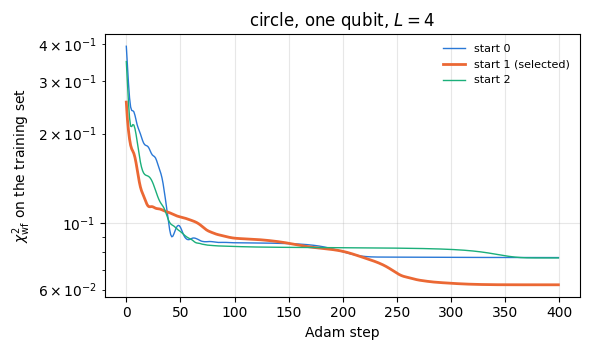

In [13]:
# ==============================================================================
# STEP 7: Adam training loop, compiled with lax.scan and vmapped over random starts
# ==============================================================================
N_STARTS, LR = 3, 0.05


@partial(jax.jit, static_argnames=("cfg", "cost", "n_steps"))
def train(P0, pts, y, cfg, cost, n_steps, lr=LR):
    """Adam on the cost `cost` ('f' or 'wf') from every row of P0.

    JAX    value_and_grad gives cost and exact gradient in one reverse pass; lax.scan compiles the n_steps updates
           into one loop; vmap runs all starts in one call.  cfg = (Q, L, d, C, entangle) is static: it fixes the
           shapes and the gate sequence.
    Returns the final parameters (K, n_params) and the cost histories (K, n_steps).
    """
    vg = jax.value_and_grad(COSTS[cost])

    def run(p0):
        def step(carry, _):
            p, st = carry
            v, g = vg(p, pts, y, cfg)
            p, st = adam_update(p, g, st, lr=lr)
            return (p, st), v
        (p, _), hist = lax.scan(step, (p0, adam_init(p0)), None, length=n_steps)
        return p, hist
    return jax.vmap(run)(P0)


def fit(problem, Q, L, cost="wf", entangle=False, n_steps=400, n_starts=N_STARTS, seed=0):
    """Train one classifier; return the best start (by final training cost), its histories and its accuracies."""
    d = DATA[problem]
    cfg = (Q, L, 2, d["C"], bool(entangle))
    P0 = init_params(jax.random.PRNGKey(1000 * Q + 10 * L + seed), n_starts, Q, L, 2, d["C"])
    P, hist = train(P0, d["Xtr"], d["ytr"], cfg, cost, n_steps)
    b = int(jnp.argmin(hist[:, -1]))
    pred = predict(P[b], jnp.concatenate([d["Xtr"], d["Xte"]]), cfg, cost)      # one call for both sets
    return dict(p=P[b], cfg=cfg, cost=cost, hist=np.asarray(hist), best=b,
                acc_train=float(jnp.mean(pred[:M_TRAIN] == d["ytr"])),
                acc_test=float(jnp.mean(pred[M_TRAIN:] == d["yte"])))


t0 = time.perf_counter()
demo = fit("circle", 1, 4, "wf", n_steps=400)
print(f"circle, Q = 1, L = 4, chi2_wf, {N_STARTS} starts x 400 steps: {time.perf_counter() - t0:.1f} s (incl. compilation)")
print("final training costs:", np.round(demo["hist"][:, -1], 4), "-> best start", demo["best"])
print(f"best start: training accuracy {100 * demo['acc_train']:.1f} %, test accuracy {100 * demo['acc_test']:.1f} %")

fig, ax = plt.subplots(figsize=(6, 3.6))
for k in range(N_STARTS):
    ax.plot(demo["hist"][k], color=PALETTE[k], lw=2.0 if k == demo["best"] else 1.0,
            label=f"start {k}" + (" (selected)" if k == demo["best"] else ""))
ax.set_yscale("log")
ax.set_xlabel("Adam step")
ax.set_ylabel(r"$\chi^2_{\rm wf}$ on the training set")
ax.set_title(r"circle, one qubit, $L=4$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The training curves fall steeply during the first hundred steps and flatten afterwards. Different starts end at
different values of the cost, the signature of the local minima mentioned above, and the start with the lowest final
cost is kept. Start 1 is not the lowest at step 150; it leaves a plateau near step 200 and overtakes the other two,
so the ranking of the starts is known only at the end of the run. The training and test accuracies of the selected start are close to each other: with 22 parameters and
200 training points the classifier does not memorise the training set.

In [14]:
section_timer("7 single-qubit results")

## 7. One qubit: accuracy against the number of layers

### 7.1 The circle

The cell trains the single-qubit classifier with both costs for $L=1,2,3,4,6,8,10$ and prints the test accuracy next
to the paper's Table 1 (single qubit, L-BFGS-B). The paper also lists $L=5$; we skip it to save time.

circle: test accuracy of the single-qubit classifier (this notebook / paper)
   L       chi2_f            chi2_wf    
   1       0.734 / 0.50       0.751 / 0.50
   2       0.789 / 0.85       0.910 / 0.94
   3       0.790 / 0.85       0.917 / 0.94
   4       0.879 / 0.90       0.929 / 0.94
   6       0.862 / 0.92       0.954 / 0.95
   8       0.919 / 0.93       0.974 / 0.97
  10       0.941 / 0.95       0.983 / 0.96


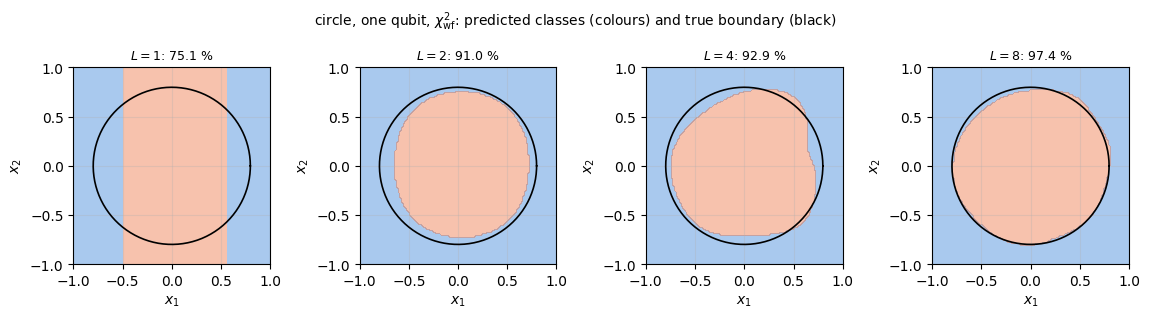

In [15]:
# ==============================================================================
# STEP 8: single qubit, accuracy vs L, both costs, circle
# ==============================================================================
LAYERS_1Q = (1, 2, 3, 4, 6, 8, 10)
N_STEPS_1Q = 400
# paper, single qubit (Tables 1, 6, 4), L = 1, 2, 3, 4, 5, 6, 8, 10; we use the entries for LAYERS_1Q
PAPER_L = (1, 2, 3, 4, 5, 6, 8, 10)
PAPER_1Q = {("circle", "f"): (0.50, 0.85, 0.85, 0.90, 0.89, 0.92, 0.93, 0.95),
            ("circle", "wf"): (0.50, 0.94, 0.94, 0.94, 0.96, 0.95, 0.97, 0.96),
            ("non-convex", "f"): (0.49, 0.82, 0.93, 0.93, 0.91, 0.96, 0.96, 0.95),
            ("non-convex", "wf"): (0.49, 0.86, 0.96, 0.95, 0.97, 0.98, 0.98, 0.96),
            ("annulus", "f"): (0.34, 0.57, 0.80, 0.84, 0.92, 0.93, 0.90, 0.90),
            ("annulus", "wf"): (0.43, 0.76, 0.68, 0.79, 0.88, 0.91, 0.92, 0.93)}


def paper_value(table, L):
    return table[PAPER_L.index(L)]


RES_1Q = {}
for cost in ("f", "wf"):
    for L in LAYERS_1Q:
        RES_1Q[("circle", cost, L)] = fit("circle", 1, L, cost, n_steps=N_STEPS_1Q)


def print_table(problem, costs):
    print(f"{problem}: test accuracy of the single-qubit classifier (this notebook / paper)")
    print("   L  " + "  ".join(f"     chi2_{c:2s}    " for c in costs))
    for L in LAYERS_1Q:
        row = [f"{RES_1Q[(problem, c, L)]['acc_test']:.3f} / {paper_value(PAPER_1Q[(problem, c)], L):.2f}" for c in costs]
        print(f"  {L:2d}  " + "  ".join(f"{r:>17s}" for r in row))


print_table("circle", ("f", "wf"))


def plot_regions(results, problem, title, ncols=4):
    """Predicted class regions on a 121 x 121 grid for a list of trained classifiers."""
    g = np.linspace(-1, 1, 121)
    G = jnp.asarray(np.stack(np.meshgrid(g, g), -1).reshape(-1, 2))
    C = PROBLEMS[problem]
    fig, axes = plt.subplots(1, len(results), figsize=(2.9 * len(results), 3.1))
    for ax, (lab, r) in zip(np.atleast_1d(axes), results):
        pred = np.asarray(predict(r["p"], G, r["cfg"], r["cost"])).reshape(121, 121)
        ax.contourf(g, g, pred, levels=np.arange(C + 1) - 0.5, colors=PALETTE[:C], alpha=0.4)
        draw_boundaries(ax, problem)
        ax.set_title(f"{lab}: {100 * r['acc_test']:.1f} %", fontsize=9)
        ax.set_xlabel("$x_1$")
        ax.set_ylabel("$x_2$")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    plt.show()


plot_regions([(f"$L={L}$", RES_1Q[("circle", "wf", L)]) for L in (1, 2, 4, 8)], "circle",
             r"circle, one qubit, $\chi^2_{\rm wf}$: predicted classes (colours) and true boundary (black)")

The one-layer classifier draws exactly the vertical strip of Section 4.2 and reaches $75.1\,\%$, against $0.50$ in
the paper. With two layers the region is already round ($91.0\,\%$), and with eight it follows the circle
($97.4\,\%$). The weighted fidelity cost beats the fidelity cost at every $L$, by $12$–$13$ percentage points at
$L=2,3$, in agreement with the paper, where the gap is $9$ points at $L=2$. For $L=2$–$4$ our accuracies lie
1–3 points below the paper's ($0.910$–$0.929$ against $0.94$), for $L\geq8$ they are equal or slightly higher
($0.974$ and $0.983$ against $0.97$ and $0.96$).

The two sets of numbers come from different training sets, different random starts and different optimisers, and
can be expected to agree in their trends; digit-by-digit agreement is not expected. The test accuracy has a
sampling uncertainty of about $0.004$, but the choice of the 200 training points and the local minimum reached move
it by more: the paper's own table decreases from $0.96$ to $0.95$ between $L=5$ and $6$, and our $\chi^2_{\rm f}$ column from $0.879$ to $0.862$ between $L=4$
and $6$. Neither optimiser finds the global minimum of a landscape full of local minima, and a deeper circuit does
not guarantee a better result after a finite training.

### 7.2 The non-convex boundary and the annulus

The same scan for the two harder problems, with the weighted fidelity cost only, which the paper finds better on
both.

non-convex: test accuracy of the single-qubit classifier (this notebook / paper)
   L       chi2_wf    
   1       0.517 / 0.49
   2       0.765 / 0.86
   3       0.960 / 0.96
   4       0.945 / 0.95
   6       0.951 / 0.98
   8       0.976 / 0.98
  10       0.962 / 0.96


annulus: test accuracy of the single-qubit classifier (this notebook / paper)
   L       chi2_wf    
   1       0.636 / 0.43
   2       0.681 / 0.76
   3       0.726 / 0.68
   4       0.788 / 0.79
   6       0.914 / 0.91
   8       0.935 / 0.92
  10       0.925 / 0.93


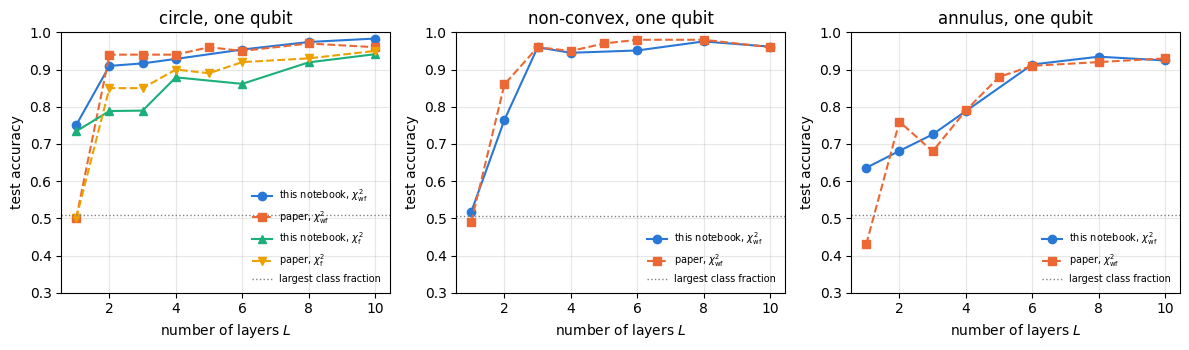

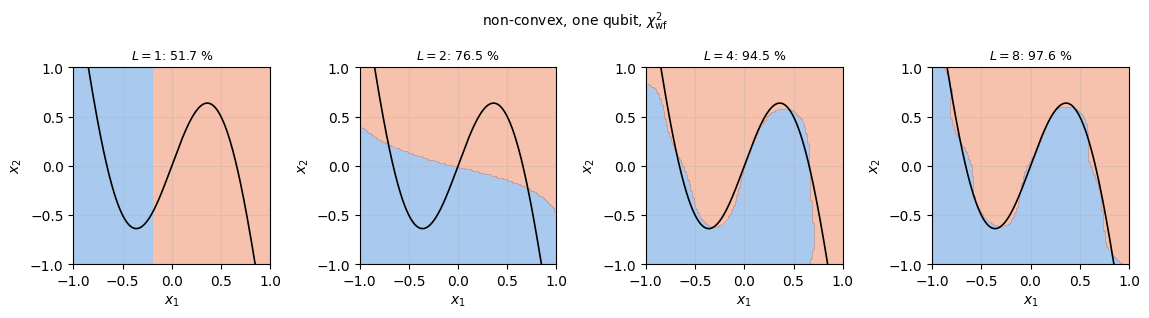

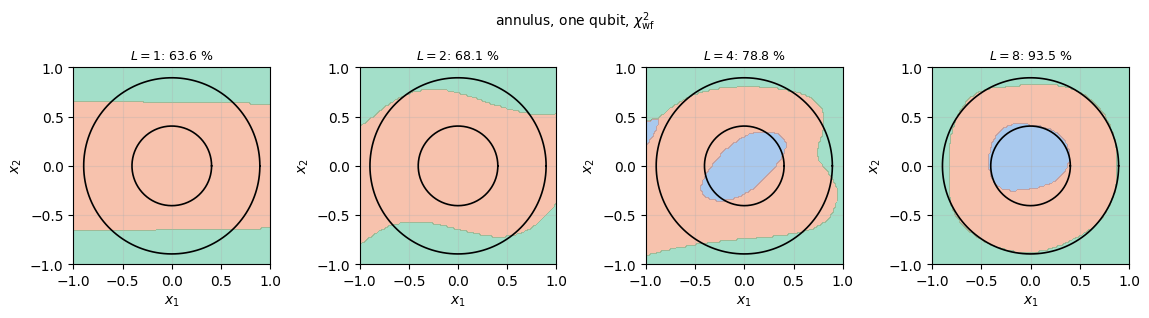

In [16]:
# ==============================================================================
# STEP 9: single qubit, accuracy vs L, weighted fidelity cost, non-convex and annulus
# ==============================================================================
for problem in ("non-convex", "annulus"):
    for L in LAYERS_1Q:
        RES_1Q[(problem, "wf", L)] = fit(problem, 1, L, "wf", n_steps=N_STEPS_1Q)
    print_table(problem, ("wf",))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, problem in zip(axes, PROBLEMS):
    ax.plot(LAYERS_1Q, [RES_1Q[(problem, "wf", L)]["acc_test"] for L in LAYERS_1Q], "o-", color=PALETTE[0],
            label=r"this notebook, $\chi^2_{\rm wf}$")
    ax.plot(PAPER_L, PAPER_1Q[(problem, "wf")], "s--", color=PALETTE[1], label=r"paper, $\chi^2_{\rm wf}$")
    if problem == "circle":
        ax.plot(LAYERS_1Q, [RES_1Q[(problem, "f", L)]["acc_test"] for L in LAYERS_1Q], "^-", color=PALETTE[2],
                label=r"this notebook, $\chi^2_{\rm f}$")
        ax.plot(PAPER_L, PAPER_1Q[(problem, "f")], "v--", color=PALETTE[3], label=r"paper, $\chi^2_{\rm f}$")
    ax.axhline(max(float(jnp.mean(DATA[problem]["yte"] == c)) for c in range(PROBLEMS[problem])), color="0.5",
               lw=1, ls=":", label="largest class fraction")
    ax.set_xlabel("number of layers $L$")
    ax.set_ylabel("test accuracy")
    ax.set_title(f"{problem}, one qubit")
    ax.set_ylim(0.3, 1.0)
    ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

plot_regions([(f"$L={L}$", RES_1Q[("non-convex", "wf", L)]) for L in (1, 2, 4, 8)], "non-convex",
             r"non-convex, one qubit, $\chi^2_{\rm wf}$")
plot_regions([(f"$L={L}$", RES_1Q[("annulus", "wf", L)]) for L in (1, 2, 4, 8)], "annulus",
             r"annulus, one qubit, $\chi^2_{\rm wf}$")

On the non-convex problem the single qubit goes from a vertical cut at $L=1$ ($51.7\,\%$) to a boundary that follows
both wiggles of the sine at $L=4$ ($94.5\,\%$) and reaches $97.6\,\%$ at $L=8$; the paper's column is matched to
within one point for $L=3,4,8,10$, while at $L=2$ ($76.5$ against $86\,\%$) and $L=6$ ($95.1$ against $98\,\%$) we
stopped in a worse minimum.

The annulus is the hardest case. With one or two layers the classifier finds horizontal bands and no inner disc
(inner class $12\,\%$ of the points). The bands depend on $x_2$ already at $L=1$, unlike the strip of the circle,
because two of the three label states lie off the $z$ axis, so their fidelities depend on the azimuth, which carries
$x_2$. At $L=4$ a tilted inner region appears, and at $L=8$ the three regions are concentric, with $93.5\,\%$; the
paper describes the same progression (four layers to "learn that there are three concentric patterns", its Fig. 8). From $L=4$ on, our accuracies agree with the paper's to within two points
($0.788$, $0.914$, $0.935$, $0.925$ against $0.79$, $0.91$, $0.92$, $0.93$). At $L=1$ we obtain $0.636$ against
$0.43$, at $L=2$ $0.681$ against $0.76$. The paper's column is non-monotonic at small $L$ ($0.76$ at $L=2$, $0.68$
at $L=3$), ours at large $L$ ($0.935$ at $L=8$, $0.925$ at $L=10$), a sign of local minima.

Two features are robust across both sets of numbers: a single qubit needs four to eight uploads to reach about
$93$–$98\,\%$ on these problems, and beyond that the accuracy saturates; the remaining errors lie along the
boundaries, where 200 training points leave the exact position of the boundary undetermined.

In [17]:
section_timer("8 multi-qubit")

## 8. Several qubits, with and without entanglement

### 8.1 The circuits of the paper

The paper generalises the classifier to $Q=2$ and $Q=4$ qubits (its Figs. 4 and 5):

* **upload on every qubit.** In each layer every qubit $q$ receives its own compressed rotation
  $U(\boldsymbol\theta_{q,l}+\mathbf w_{q,l}\circ\mathbf x)$ with its own angles and weights; the same data point is
  uploaded on all qubits in every layer. A layer therefore has $Q$ times the parameters of the single-qubit layer;
* **entanglers between layers.** In the entangled version, CZ gates follow every layer except the last. For two
  qubits this is one CZ between qubits 0 and 1; for four qubits two CZ gates alternate between the pairs $(0,1),(2,3)$
  after odd layers and $(1,2),(0,3)$ after even layers, so that after two layers every qubit is linked to both
  neighbours on a ring. Without the CZ gates the qubits never interact.

Figure 2 shows the four-qubit entangled circuit. The CZ gate is diagonal,
$\mathrm{CZ}=\mathrm{diag}(1,1,1,-1)$: it changes the sign of $\vert11\rangle$ only. It has no effect on a product of
computational basis states, but on superpositions it creates entanglement, and the trainable rotations before and
after it decide how much. The paper places no entangler after the last layer. For two classes with the label
states $\vert0\rangle,\vert1\rangle$ it would have no effect anyway: a diagonal gate does not change the
computational-basis populations, and these are the fidelities with $\vert0\rangle$ and $\vert1\rangle$.

![Four-qubit re-uploading classifier with entanglement: every layer applies a compressed rotation U_{q,l} on each of the four qubits, followed by CZ gates on the pairs (0,1),(2,3) after layer 1 and (1,2),(0,3) after layer 2, alternating; the last layer has no CZ; every qubit is measured and its reduced state gives the fidelities F_{c,q}](figures/reuploading_four_qubits.svg)\
**Figure 2.** The four-qubit classifier with entanglement (paper, Fig. 5b). $U_{q,l}=U(\boldsymbol\theta_{q,l}+\mathbf w_{q,l}\circ\mathbf x)$
uploads the data on qubit $q$ in layer $l$. The CZ gates alternate between the pairs $(0,1),(2,3)$ and $(1,2),(0,3)$.
The fidelities $F_{c,q}$ of the reduced state of each qubit with the label states enter the cost of Eq. (16).

### 8.2 Labels and fidelities on several qubits

The label states stay single-qubit states. Each qubit $q$ is described by its reduced density matrix
$\rho_q(\mathbf x)=\mathrm{Tr}_{\bar q}\vert\psi(\mathbf x)\rangle\langle\psi(\mathbf x)\vert$, and its fidelity with
label state $c$ is (paper, Eq. (22))

$$F_{c,q}(\mathbf x)=\langle\tilde\psi_c\vert\rho_q(\mathbf x)\vert\tilde\psi_c\rangle . \tag{13}$$

Writing $\rho_q=\frac12(\mathbb 1+\mathbf r_q\cdot\boldsymbol\sigma)$ with the Bloch vector $\mathbf r_q$ of the
qubit gives

$$F_{c,q}=\tfrac12\big(1+\mathbf n_c\cdot\mathbf r_q\big),\qquad \vert\mathbf r_q\vert^2=2\,\mathrm{Tr}\rho_q^2-1 . \tag{14}$$

Without entanglers every $\rho_q$ is pure, $\vert\mathbf r_q\vert=1$, and the multi-qubit classifier is $Q$
independent single-qubit classifiers whose outputs are combined only in the cost. With entanglers $\rho_q$ is in
general mixed, $\vert\mathbf r_q\vert<1$, and Eq. (14) shows the consequence: a fidelity can reach 1 only on the
surface of the Bloch sphere,

$$F_{c,q}\leq\tfrac12\big(1+\vert\mathbf r_q\vert\big)<1 . \tag{15}$$

The scores of the weighted cost combine the qubits with weights $\alpha_{c,q}$,

$$\chi^2_{\rm wf}=\frac1{2M}\sum_{\mu=1}^{M}\sum_{c=1}^{C}\Big(\sum_{q=1}^{Q}\alpha_{c,q}F_{c,q}(\mathbf x_\mu)-Y_c(s_\mu)\Big)^2, \tag{16}$$

and the prediction is the class with the largest $\sum_q\alpha_{c,q}F_{c,q}$. Eq. (16) and this prediction rule are
what the authors' published code computes: it sums the weighted fidelities over the qubits before comparing with
$Y_c$. The paper's printed Eq. (23) places the sum over $q$ outside the square, fitting each qubit to $Y_c$
separately. This is what `chi2_wf` and `scores` of Section 5.4 already compute: `fidelities` returns the array
$F_{c,q}$ from the engine's `rdm`. With $Q=1$ every formula reduces to Section 5. (The paper's first strategy for
several qubits is the fidelity cost with computational basis states of all qubits as label states; its four-qubit
results are given only for the weighted cost, the second strategy, and we use $\chi^2_{\rm wf}$ throughout.)

Four checks before training, for two and four qubits with $L=3$: without CZ gates each qubit must give exactly the
fidelities of a single-qubit circuit with that qubit's parameters; with CZ gates the scanned circuit with sign
patterns (Section 5.2) must agree with an explicit loop that applies every gate with `apply_gate`; the reduced states
must have unit trace; and their purity must drop below one, Eq. (14).

In [18]:
# ==============================================================================
# STEP 10: checks of the multi-qubit circuit
# ==============================================================================
d = DATA["annulus"]
pts5 = d["Xtr"][:50]
for Q in (2, 4):
    cfgQ = (Q, 3, 2, 3, False)
    pQ = init_params(jax.random.PRNGKey(20 + Q), 1, *cfgQ[:4])[0]
    thQ, wQ, _ = unpack(pQ, *cfgQ[:4])
    F_multi = fidelities(pQ, pts5, cfgQ)                                       # (50, C, Q)
    err_prod = 0.0
    for q in range(Q):
        p1 = jnp.concatenate([thQ[q].ravel(), wQ[q].ravel(), jnp.ones(3, RDTYPE)])
        F_single = fidelities(p1, pts5, (1, 3, 2, 3, False))[:, :, 0]
        err_prod = max(err_prod, max_abs(F_multi[:, :, q] - F_single))
    print(f"Q = {Q}, no CZ: max |F_cq - F_c of a single qubit with the same parameters| = {err_prod:.2e}")
    assert err_prod < TOL

    psiE = jax.vmap(lambda x: classifier_state(thQ, wQ, x, True))(pts5)

    def explicit(x):                     # reference: Python loops, every CZ applied with apply_gate
        psi = zero_state(Q)
        for l in range(3):
            for q in range(Q):
                psi = apply_gate(psi, u3_euler(layer_angles(thQ[q, l], wQ[q, l], x)), [q])
            if l < 2:
                for pair in CZ_PAIRS[Q][l % 2]:
                    psi = apply_gate(psi, CZ, list(pair))
        return psi
    err_cz = max_abs(psiE - jax.vmap(explicit)(pts5))
    print(f"Q = {Q}, with CZ: max |scan with sign patterns - explicit CZ gates| = {err_cz:.2e}")
    assert err_cz < TOL
    rhos = jax.vmap(lambda s: jnp.stack([rdm(s, [q]) for q in range(Q)]))(psiE)     # (50, Q, 2, 2)
    err_tr = max_abs(jnp.trace(rhos, axis1=2, axis2=3) - 1.0)
    pur = jnp.real(jnp.einsum("mqab,mqba->mq", rhos, rhos))
    print(f"Q = {Q}, with CZ: max |Tr rho_q - 1| = {err_tr:.2e},  purity Tr rho_q^2 over 50 points and {Q} qubits: "
          f"min {float(pur.min()):.3f}, mean {float(pur.mean()):.3f}")
    assert err_tr < TOL and float(pur.min()) < 1 - 1e-3

Q = 2, no CZ: max |F_cq - F_c of a single qubit with the same parameters| = 8.88e-16


Q = 2, with CZ: max |scan with sign patterns - explicit CZ gates| = 5.47e-16


Q = 2, with CZ: max |Tr rho_q - 1| = 8.88e-16,  purity Tr rho_q^2 over 50 points and 2 qubits: min 0.608, mean 0.935


Q = 4, no CZ: max |F_cq - F_c of a single qubit with the same parameters| = 9.99e-16


Q = 4, with CZ: max |scan with sign patterns - explicit CZ gates| = 5.59e-16


Q = 4, with CZ: max |Tr rho_q - 1| = 8.88e-16,  purity Tr rho_q^2 over 50 points and 4 qubits: min 0.503, mean 0.792


Without CZ gates each qubit of the two- and four-qubit circuits behaves exactly as a lone qubit with the same
parameters, and the sign-pattern implementation of the CZ gates reproduces the gate-by-gate circuit. With the CZ
gates the reduced states keep unit trace but are mixed, with purities well below one at
random parameters: the entanglers produce entanglement, and by Eq. (15) the individual fidelities are then bounded
away from one.

### 8.3 Training with two and four qubits

The cell trains the multi-qubit classifiers on the circle for $L=2,3,4$ and on the annulus for $L=1,2,3,4$, with and
without CZ gates (with $L=1$ there is nothing to entangle, since no CZ follows the last layer), and prints the test
accuracy next to the paper's Tables 1 and 4. On the circle the case $L=1$ is not trained: Section 9 shows that its
accuracy cannot exceed $75.8\,\%$ for any number of qubits. A four-qubit layer costs several times as much as a
single-qubit layer (Section 11), so we use two random starts here, with 300 Adam steps on the circle and 600 on the
annulus.

In [19]:
# ==============================================================================
# STEP 11: 2 and 4 qubits, with and without CZ, circle and annulus, weighted fidelity cost
# ==============================================================================
LAYERS_MQ = {"circle": (2, 3, 4), "annulus": (1, 2, 3, 4)}   # circle L = 1 is fixed by the x1-only bound (Section 9)
N_STEPS_MQ, N_STARTS_MQ = {"circle": 300, "annulus": 600}, 2       # Adam steps per problem, random starts
# paper, chi2_wf, L = 1, 2, 3, 4 (Table 1: circle, Table 4: annulus); None = no entangled version for L = 1
PAPER_MQ = {("circle", 2, False): (0.76, 0.96, 0.97, 0.97), ("circle", 2, True): (None, 0.96, 0.95, 0.96),
            ("circle", 4, False): (0.76, 0.96, 0.97, 0.97), ("circle", 4, True): (None, 0.96, 0.96, 0.96),
            ("annulus", 2, False): (0.77, 0.79, 0.94, 0.93), ("annulus", 2, True): (None, 0.82, 0.95, 0.96),
            ("annulus", 4, False): (0.81, 0.87, 0.92, 0.93), ("annulus", 4, True): (None, 0.96, 0.94, 0.96)}
RES_MQ = {}
for problem in ("circle", "annulus"):
    for Q in (2, 4):
        for ent in (False, True):
            for L in LAYERS_MQ[problem]:
                if ent and L == 1:
                    continue
                t0 = time.perf_counter()
                RES_MQ[(problem, Q, ent, L)] = fit(problem, Q, L, "wf", ent, n_steps=N_STEPS_MQ[problem],
                                                     n_starts=N_STARTS_MQ)
                RES_MQ[(problem, Q, ent, L)]["time"] = time.perf_counter() - t0

for problem in ("circle", "annulus"):
    print(f"\n{problem}: test accuracy, chi2_wf (this notebook / paper)")
    print("   L      1 qubit      " + "  ".join(f"{Q} qubits {'CZ' if e else 'no CZ':5s}" for Q in (2, 4) for e in (False, True)))
    for i, L in enumerate((1, 2, 3, 4)):
        row = [f"{RES_1Q[(problem, 'wf', L)]['acc_test']:.3f} / {paper_value(PAPER_1Q[(problem, 'wf')], L):.2f}"]
        for Q in (2, 4):
            for ent in (False, True):
                if (problem, Q, ent, L) not in RES_MQ:
                    row.append("        -        ")
                else:
                    row.append(f"{RES_MQ[(problem, Q, ent, L)]['acc_test']:.3f} / {PAPER_MQ[(problem, Q, ent)][i]:.2f}")
        print(f"  {L:2d}  " + "  ".join(f"{r:>17s}" for r in row))
print()
for problem in ("circle", "annulus"):
    n = N_STEPS_MQ[problem]
    drop = [1 - r["hist"][r["best"], -1] / r["hist"][r["best"], -n // 10 - 1]
            for k, r in RES_MQ.items() if k[0] == problem]
    print(f"{problem}: relative decrease of the training cost over the last {n // 10} of {n} steps (selected starts): "
          f"median {np.median(drop):.3f}, max {np.max(drop):.3f}")
t_mq = sum(r["time"] for r in RES_MQ.values())
print(f"\ntraining time of the {len(RES_MQ)} multi-qubit classifiers (incl. compilation): {t_mq:.0f} s")


circle: test accuracy, chi2_wf (this notebook / paper)
   L      1 qubit      2 qubits no CZ  2 qubits CZ     4 qubits no CZ  4 qubits CZ   
   1       0.751 / 0.50          -                  -                  -                  -        
   2       0.910 / 0.94       0.939 / 0.96       0.954 / 0.96       0.945 / 0.96       0.955 / 0.96
   3       0.917 / 0.94       0.954 / 0.97       0.964 / 0.95       0.946 / 0.97       0.966 / 0.96
   4       0.929 / 0.94       0.979 / 0.97       0.974 / 0.96       0.977 / 0.97       0.980 / 0.96

annulus: test accuracy, chi2_wf (this notebook / paper)
   L      1 qubit      2 qubits no CZ  2 qubits CZ     4 qubits no CZ  4 qubits CZ   
   1       0.636 / 0.43       0.771 / 0.77          -               0.795 / 0.81          -        
   2       0.681 / 0.76       0.912 / 0.79       0.824 / 0.82       0.930 / 0.87       0.924 / 0.96
   3       0.726 / 0.68       0.896 / 0.94       0.897 / 0.95       0.934 / 0.92       0.939 / 0.94
   4       0.78

**Circle.** All multi-qubit classifiers reach $94$–$98\,\%$ from $L=2$ on, the paper's $0.95$–$0.97$. The CZ gates
raise the accuracy at $L=2$ and $3$ by one to two points ($0.939\to0.954$ and $0.954\to0.964$ for two qubits,
$0.945\to0.955$ and $0.946\to0.966$ for four) and change it by less than one point at $L=4$; the paper finds no effect of entanglement on this problem.
The paper's one-layer value for two and four qubits, $0.76$, coincides with the bound of Section 9.

**Annulus.** Two and four qubits do much better than one at small $L$: at $L=2$, $0.82$–$0.93$ against $0.68$ for a
single qubit, and at $L=4$, $0.90$–$0.94$ against $0.79$. This agrees with the paper's statement that more qubits
reach a given accuracy with fewer layers. The training has nearly levelled off: over the last 60 of the 600 steps
the cost of the selected start fell by a median $1.3\,\%$ and at most $10.7\,\%$. The CZ gates change the accuracy
by less than one point for four qubits at $L=2$ ($0.930\to0.924$) and lower it by nine points for two
($0.912\to0.824$); at $L=3,4$ the differences are up to four points with either sign ($+0.1$ and $+2.5$ points for
two qubits, $+0.5$ and $-3.9$ for four). The paper's entangled four-qubit classifier reaches $0.96$ at $L=2$ against
$0.87$ without CZ; we obtain $0.924$ with CZ and $0.930$ without.

Compared with the paper, our non-entangled classifiers are better at $L=2$ ($0.912$ and $0.930$ against $0.79$ and
$0.87$) and within about four points elsewhere, the largest gap being $0.896$ against $0.94$ for two qubits at
$L=3$. Our entangled classifiers lie below the paper's in five of the six cases, by $0.1$ to six points
($0.924$ against $0.96$ at $L=2$; $0.897$ against $0.95$ and $0.939$ against $0.94$ at $L=3$; $0.942$ against $0.96$
and $0.899$ against $0.96$ at $L=4$), and at the paper's value in the sixth ($0.824$ against $0.82$, two qubits at
$L=2$). The optimiser, the initialisation, the training set and the number of starts all differ from the paper's,
and two starts per classifier sample few of the local minima, so differences of a few points in either direction
are within what these differences can produce.

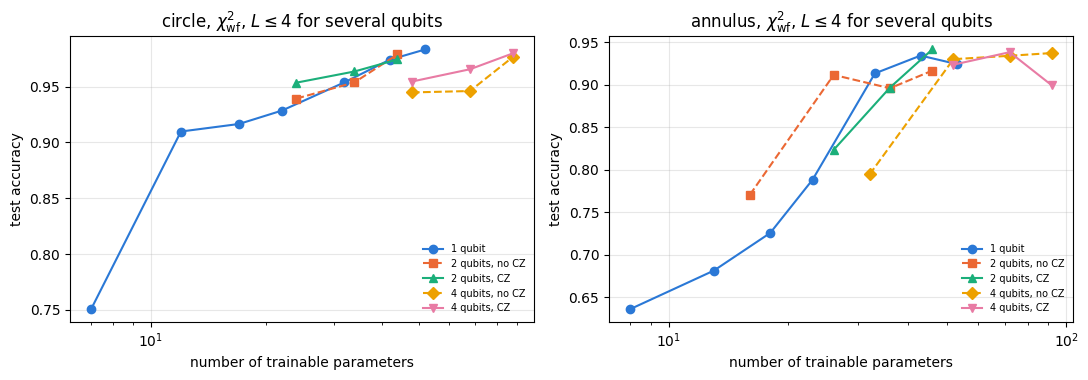

circle   Q = 2, CZ, L = 4: mean purity of rho_q on 1000 test points per qubit 0.833, 0.833


circle   Q = 4, CZ, L = 4: mean purity of rho_q on 1000 test points per qubit 0.779, 0.796, 0.856, 0.837
annulus  Q = 2, CZ, L = 4: mean purity of rho_q on 1000 test points per qubit 0.836, 0.836
annulus  Q = 4, CZ, L = 4: mean purity of rho_q on 1000 test points per qubit 0.785, 0.822, 0.706, 0.693


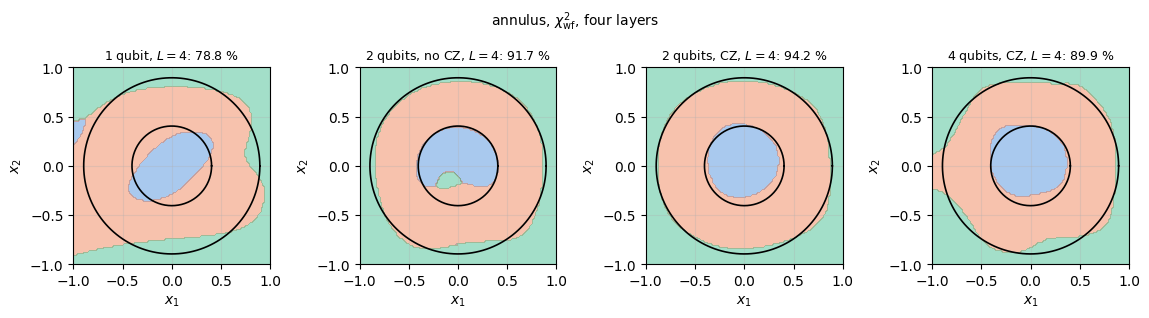

In [20]:
# ==============================================================================
# STEP 12: accuracy vs number of parameters, and what the entanglers do to the reduced states
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, problem in zip(axes, ("circle", "annulus")):
    C = PROBLEMS[problem]
    ax.plot([n_params(1, L, 2, C) for L in LAYERS_1Q], [RES_1Q[(problem, "wf", L)]["acc_test"] for L in LAYERS_1Q],
            "o-", color=PALETTE[0], label="1 qubit")
    for j, (Q, ent) in enumerate([(2, False), (2, True), (4, False), (4, True)]):
        Ls = [L for L in LAYERS_MQ[problem] if (problem, Q, ent, L) in RES_MQ]
        ax.plot([n_params(Q, L, 2, C) for L in Ls], [RES_MQ[(problem, Q, ent, L)]["acc_test"] for L in Ls],
                MARKERS[j + 1] + ("-" if ent else "--"), color=PALETTE[j + 1],
                label=f"{Q} qubits, {'CZ' if ent else 'no CZ'}")
    ax.set_xscale("log")
    ax.set_xlabel("number of trainable parameters")
    ax.set_ylabel("test accuracy")
    ax.set_title(f"{problem}, $\\chi^2_{{\\rm wf}}$, $L\\leq4$ for several qubits")
    ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

# purity of the reduced states of the trained entangled classifiers on the test set
@jax.jit
def purities(theta, w, pts):
    """Tr rho_q^2 for every point and qubit of the entangled classifier, shape (M, Q)."""
    def one(x):
        psi = classifier_state(theta, w, x, True)
        return jnp.stack([jnp.real(jnp.trace(rdm(psi, [q]) @ rdm(psi, [q]))) for q in range(theta.shape[0])])
    return jax.vmap(one)(pts)


for problem in ("circle", "annulus"):
    for Q in (2, 4):
        r = RES_MQ[(problem, Q, True, 4)]
        th, w, _ = unpack(r["p"], *r["cfg"][:4])
        pur = purities(th, w, DATA[problem]["Xte"][:1000])
        print(f"{problem:8s} Q = {Q}, CZ, L = 4: mean purity of rho_q on 1000 test points per qubit "
              + ", ".join(f"{v:.3f}" for v in np.asarray(pur.mean(0))))

plot_regions([("1 qubit, $L=4$", RES_1Q[("annulus", "wf", 4)]),
              ("2 qubits, no CZ, $L=4$", RES_MQ[("annulus", 2, False, 4)]),
              ("2 qubits, CZ, $L=4$", RES_MQ[("annulus", 2, True, 4)]),
              ("4 qubits, CZ, $L=4$", RES_MQ[("annulus", 4, True, 4)])], "annulus",
             r"annulus, $\chi^2_{\rm wf}$, four layers")

**Accuracy per parameter.** Plotted against the number of trainable parameters, the advantage of several qubits
disappears. On the annulus the single qubit with $L=6$ (33 parameters) reaches $91.4\,\%$ and the two-qubit
classifiers with $L=3$ (36 parameters) $89.6$–$89.7\,\%$; the four-qubit classifiers with $L=2$ (52 parameters)
reach $92.4$–$93.0\,\%$, like the single qubit with $L=10$ (53 parameters, $92.5\,\%$). On the circle the curves
overlap. More qubits buy a shorter circuit for the same accuracy because they carry more parameters per layer; per
parameter they are no more efficient than a single qubit.

**The entanglers are used.** In the trained entangled classifiers the mean purity of the one-qubit reduced states on
the test set is $0.69$–$0.86$, far from the value 1 of a product state. By Eq. (14), a purity $0.83$ means
$\vert\mathbf r_q\vert=\sqrt{2\cdot0.83-1}=0.81$ and, by Eq. (15), fidelities of at most $0.91$; the class weights
$\alpha_{c,q}$ can rescale them towards the targets $Y_c$. The decision regions for the annulus with four layers
show the gain from more qubits: the tilted inner region of the single qubit becomes a disc.

In [21]:
section_timer("9-10 entanglement, expressivity")

## 9. The role of entanglement and of the number of layers

The experiments of Section 8 and the structure of the circuits give three answers.

**Without CZ gates, several qubits are a sum of single-qubit classifiers.** Each qubit evolves on its own, and the
score $\sum_q\alpha_{c,q}F_{c,q}(\mathbf x)$ is a weighted sum of $Q$ functions, each of which a lone qubit could
compute. This is closer to the neural network of Eq. (1), where neuron outputs are summed, than the single qubit is.

**The number of layers limits what any number of qubits can do.** The cleanest case is $L=1$ with two classes. With
label states $\vert0\rangle,\vert1\rangle$ the fidelities of qubit $q$ are $\cos^2\frac{\phi_{1}}2$ and
$\sin^2\frac{\phi_1}2$, with $\phi_1=\theta_{q,1,1}+w_{q,1,1}x_1$: the coordinate $x_2$ enters only the azimuth and
drops out. Every classifier with one layer, on any number of qubits (and with $L=1$ there are no CZ gates),
therefore classifies by $x_1$ alone, and on the circle it cannot beat the best rule of the form "class 1 if
$\vert x_1\vert<a$". At fixed $x_1$, with $x_2$ uniform in $[-1,1]$, a point is inside the circle with probability
$p(x_1)=\sqrt{r^2-x_1^2}$ for $\vert x_1\vert<r$ (the chord $2\sqrt{r^2-x_1^2}$ divided by the length 2 of the
interval) and $p=0$ otherwise; the best rule chooses class 1 where $p>\frac12$, i.e. $\vert x_1\vert<\sqrt{r^2-\frac14}$,
and its accuracy is the average of $\max(p,1-p)$ over $x_1\in[0,1]$. The cell evaluates it.

In [22]:
# ==============================================================================
# STEP 12b: one layer and binary labels on the z axis: the best rule that looks at x1 only
# ==============================================================================
# For L = 1 and the label states |0>, |1>, every qubit's fidelities depend on x only through phi_1 = theta_1 + w_1 x1.
# Inside the circle with probability p(x1) = sqrt(r^2 - x1^2) (for |x1| < r) at fixed x1; the best x1-only rule picks
# class 1 where p > 1/2, i.e. |x1| < a = sqrt(r^2 - 1/4), and its accuracy is the mean of max(p, 1 - p) over x1.
u = np.linspace(0, 1, 200001)
p_in = np.sqrt(np.clip(R_CIRCLE ** 2 - u ** 2, 0, None))
acc_bound = float(np.trapezoid(np.maximum(p_in, 1 - p_in), u))
a_strip = np.sqrt(R_CIRCLE ** 2 - 0.25)
d = DATA["circle"]
acc_strip_test = float(jnp.mean((jnp.abs(d["Xte"][:, 0]) < a_strip).astype(jnp.int32) == d["yte"]))
print(f"best x1-only rule |x1| < {a_strip:.4f}: accuracy {acc_bound:.4f} (exact), {acc_strip_test:.4f} on the test set")
print(f"trained one-layer single-qubit classifier on the circle (Section 7.1): {RES_1Q[('circle', 'wf', 1)]['acc_test']:.3f}")

best x1-only rule |x1| < 0.6218: accuracy 0.7580 (exact), 0.7648 on the test set
trained one-layer single-qubit classifier on the circle (Section 7.1): 0.751


The bound is $75.8\,\%$ ($76.5\,\%$ for the strip on our test sample), and the paper's two- and four-qubit results,
$0.76$, coincide with it to the two digits given. For one qubit the best $x_1$-only rule, which is all a one-layer
qubit can express here, reaches $75.8\,\%$ and our training $75.1\,\%$; the paper reports $0.50$ for this case, so
that value reflects the optimisation in the paper's run rather than a limit of the model.

**Entanglers let the measured qubit see the data uploaded on the others.** Without CZ gates the reduced state of
qubit $q$ depends only on the gates on qubit $q$. With CZ gates, the uploads on the neighbours before the last CZ
also act on it; Section 10.3 shows that this raises the number of frequencies in its output. The price is that its
reduced state becomes mixed and its fidelities are bounded by Eq. (15). On the circle the entanglers helped slightly at
$L=2$ and $3$, by $1.0$ to $2.0$ points in all four cases (two starts per classifier), and made no difference at $L=4$
($-0.5$ and $+0.3$ points); on the annulus the differences have either sign, from $-8.8$ to $+2.5$ points. On a problem not run here, the
four-dimensional hypersphere, the paper reports a clear gain from entanglement (its Table 3: $0.98$ with CZ against
$0.90$ without, four qubits, $L=2$). What the paper and this
notebook show is that the protocol works with and without entanglement; neither shows that entanglement is needed
for it.

## 10. Expressivity of re-uploading

### 10.1 The argument of the paper

The authors motivate universality by the analogy of Section 5.1 (paper, Sec. 3). Every layer is a rotation, which can
be written as a single exponential $U(\boldsymbol\phi)=e^{i\boldsymbol\omega(\boldsymbol\phi)\cdot\boldsymbol\sigma}$
with $\boldsymbol\omega$ a vector of trigonometric functions of the angles (their Eqs. (13)–(16)). With
$\boldsymbol\phi_i=\boldsymbol\theta_i+\mathbf w_i\circ\mathbf x$, the product of $L$ layers is, by the
Baker–Campbell–Hausdorff formula,

$$\mathcal U(\mathbf x)=\exp\Big[i\sum_{i=1}^{L}\boldsymbol\omega(\boldsymbol\theta_i+\mathbf w_i\circ\mathbf x)\cdot\boldsymbol\sigma+\mathcal O_{\rm corr}\Big], \tag{17}$$

where the commutator corrections $\mathcal O_{\rm corr}$ are again combinations of Pauli matrices, since
$[\sigma^a,\sigma^b]=2i\epsilon_{abc}\sigma^c$. The sum in Eq. (17) has the form of Eq. (1): the weights
$\mathbf w_i$ and biases $\boldsymbol\theta_i$ enter a bounded, nonconstant, continuous function $\boldsymbol\omega$,
and the number of layers plays the role of the number of neurons. Hornik's version of the universal approximation
theorem allows such activation functions, including, as a corollary quoted by the authors, trigonometric
polynomials. Section 3 of the paper calls the argument a motivation, and adds that more parameters are necessary to
map it onto the theorem; the paper's conclusions speak of applying the theorem to prove universality. The
corrections $\mathcal O_{\rm corr}$, and the fact that the label is read from a fidelity instead of a free linear
combination with coefficients $\alpha_i$, are not controlled by the argument. Schuld, Sweke and Meyer (2021) describe
the result as a conjecture that such models are universal function approximators.

### 10.2 The Fourier series of a re-uploading model

A sharper statement holds for one-dimensional data (Schuld, Sweke and Meyer, 2021). Consider a model that encodes a
number $x$ with the gate $S(x)=e^{-ixH}$ in each of $L$ layers, separated by arbitrary trainable unitaries
$W^{(1)},\dots,W^{(L+1)}$, and outputs $f(x)=\langle0\vert\mathcal U^\dagger(x)\,O\,\mathcal U(x)\vert0\rangle$ for an
observable $O$. In the eigenbasis of $H$, with eigenvalues $\lambda_j$, every encoding gate contributes phases
$e^{-i\lambda_jx}$ to the amplitudes and $e^{+i\lambda_kx}$ to their complex conjugates, so

$$f(x)=\sum_{\omega\in\Omega}c_\omega\,e^{i\omega x},\qquad
\Omega=\big\{(\lambda_{k_1}+\dots+\lambda_{k_L})-(\lambda_{j_1}+\dots+\lambda_{j_L})\big\}, \tag{18}$$

where the coefficients $c_\omega$ depend on the trainable unitaries and on $O$ (their Eqs. (8)–(12)). The data enter
only through the frequencies, and the frequencies are fixed by the spectrum of the encoding generator. For a Pauli
rotation, $H=\sigma/2$ with eigenvalues $\pm\frac12$, each difference of two sums of $L$ terms $\pm\frac12$ is an
integer between $-L$ and $L$, so

$$\Omega=\{-L,\dots,-1,0,1,\dots,L\}: \tag{19}$$

**a model with $L$ uploads is a truncated Fourier series of degree $L$** in $x$. One upload gives a single
frequency, $f(x)=A\cos(x+B)+C$ (for the layer of `model_1d` below exactly $\cos(x+\theta_1)$, with $A=1$, $C=0$),
which is the one-dimensional version of the plane cut of Section 4.2; each further
upload adds one harmonic. In our layer $U(\boldsymbol\theta+\mathbf w\circ\mathbf x)$ the data enter as
$R_y(\theta_1+w_1x)=R_y(\theta_1)R_y(w_1x)$, that is, through $S(x)=e^{-ixw_1\sigma^y/2}$ with eigenvalues
$\pm w_1/2$. With trainable weights the frequencies become sums $\pm w_1\pm w_2\pm\dots$ (with some terms
cancelling), which need not be integers: the weights let the model choose its frequencies, at the price of a
spectrum that is no longer a fixed Fourier series.

The cell tests Eq. (19) on a single qubit with $w=1$ fixed and the data in the polar angle,
$\phi_1=\theta_1+x$, and the remaining angles trainable. The output $f(x)=\langle Z\rangle$ is sampled at 64 points of
$[0,2\pi)$, and the discrete Fourier transform gives the coefficients $c_n$ exactly as long as the model has no
frequency above 31. For random parameters every coefficient with $\vert n\vert>L$ must vanish. Then we take a model
with $L=3$ and random parameters as a *teacher*: its output $g(x)$ is a Fourier series of degree 3 that a three-layer
model can certainly represent. We fit $g$ with student models of $L=1,\dots,4$ layers, minimising the mean-square
error on the 64 points with Adam from eight starts.

L = 1: max |c_n| for |n| <= L: 0.500,  for |n| > L: 9.28e-17


L = 2: max |c_n| for |n| <= L: 0.495,  for |n| > L: 1.28e-16


L = 3: max |c_n| for |n| <= L: 0.392,  for |n| > L: 1.25e-16


L = 5: max |c_n| for |n| <= L: 0.367,  for |n| > L: 1.19e-16
teacher |c_n|, n = 0..4: [0.3275 0.3534 0.1688 0.0242 0.    ]


best mean-square error of the fit: L = 1: 2.08e-01, L = 2: 2.51e-01, L = 3: 1.99e-31, L = 4: 2.26e-06


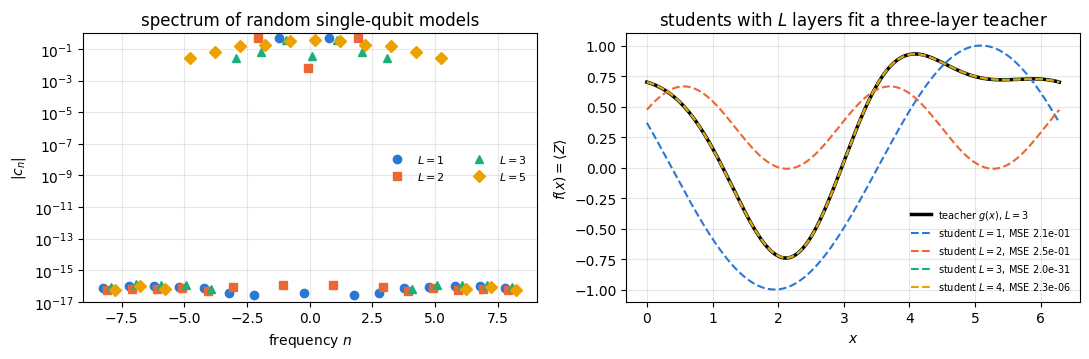

In [23]:
# ==============================================================================
# STEP 13: the Fourier spectrum of a single-qubit re-uploading model, and a fit of a degree-3 series
# ==============================================================================
N_GRID = 64
x_grid = jnp.arange(N_GRID, dtype=RDTYPE) * 2 * np.pi / N_GRID


def model_1d(theta, x):
    """f(x) = <Z> after L layers U(theta_l + (x, 0, 0)) on |0>: the data in the polar angle, weight w = 1."""
    psi = jnp.array([1.0, 0.0], dtype=CDTYPE)
    for l in range(theta.shape[0]):
        psi = u3(theta[l] + jnp.array([x, 0.0, 0.0], dtype=RDTYPE)) @ psi
    return jnp.abs(psi[0]) ** 2 - jnp.abs(psi[1]) ** 2


def fourier_coefficients(fvals):
    """c_n, n = 0..N-1 (n > N/2 are the negative frequencies), of samples f(2 pi k / N):  c_n = (1/N) sum_k f_k e^{-i n x_k}."""
    return jnp.fft.fft(fvals) / fvals.shape[0]


fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
ns = np.arange(-8, 9)
for j, L in enumerate((1, 2, 3, 5)):
    th = jax.random.uniform(jax.random.PRNGKey(300 + L), (L, 3), RDTYPE, 0, 2 * np.pi)
    c = fourier_coefficients(jax.vmap(lambda x: model_1d(th, x))(x_grid))
    n_all = np.fft.fftfreq(N_GRID, 1 / N_GRID).astype(int)
    above = max_abs(c[np.abs(n_all) > L])
    print(f"L = {L}: max |c_n| for |n| <= L: {max_abs(c[np.abs(n_all) <= L]):.3f},  for |n| > L: {above:.2e}")
    assert above < TOL
    axes[0].plot(ns + 0.15 * (j - 1.5), np.abs(np.asarray(c))[ns % N_GRID] + 1e-17, MARKERS[j], color=PALETTE[j],
                 label=f"$L={L}$")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-17, 1)
axes[0].set_xlabel("frequency $n$")
axes[0].set_ylabel(r"$|c_n|$")
axes[0].set_title("spectrum of random single-qubit models")
axes[0].legend(fontsize=8, ncol=2)


THETA_TEACHER = jax.random.uniform(jax.random.PRNGKey(333), (3, 3), RDTYPE, 0, 2 * np.pi)


def g_target(x):
    """Teacher: the output of a three-layer model with fixed random parameters (a degree-3 Fourier series)."""
    return model_1d(THETA_TEACHER, x)


c_teacher = fourier_coefficients(jax.vmap(g_target)(x_grid))
print("teacher |c_n|, n = 0..4:", np.round(np.abs(np.asarray(c_teacher[:5])), 4))


@partial(jax.jit, static_argnames=("L",))
def fit_1d(key, L):
    """Fit model_1d to the teacher on the grid: 8 starts x 1500 Adam steps (lr 0.05); returns parameters and final MSE."""
    def mse(p):
        return jnp.mean((jax.vmap(lambda x: model_1d(p.reshape(L, 3), x))(x_grid) - jax.vmap(g_target)(x_grid)) ** 2)
    vg = jax.value_and_grad(mse)

    def run(p0):
        def step(carry, _):
            p, st = carry
            v, g = vg(p)
            p, st = adam_update(p, g, st, lr=0.05)
            return (p, st), v
        (p, _), h = lax.scan(step, (p0, adam_init(p0)), None, length=1500)
        return p, mse(p)
    P0 = jax.random.uniform(key, (8, 3 * L), RDTYPE, 0, 2 * np.pi)
    return jax.vmap(run)(P0)


xf = jnp.linspace(0, 2 * np.pi, 300)
axes[1].plot(np.asarray(xf), np.asarray(jax.vmap(g_target)(xf)), "k-", lw=2.5, label="teacher $g(x)$, $L=3$")
FIT_1D = {}
for j, L in enumerate((1, 2, 3, 4)):
    P, errs = fit_1d(jax.random.PRNGKey(400 + L), L)
    b = int(jnp.argmin(errs))
    FIT_1D[L] = float(errs[b])
    axes[1].plot(np.asarray(xf), np.asarray(jax.vmap(lambda x: model_1d(P[b].reshape(L, 3), x))(xf)), "--",
                 color=PALETTE[j], label=f"student $L={L}$, MSE {FIT_1D[L]:.1e}")
print("best mean-square error of the fit: " + ", ".join(f"L = {L}: {v:.2e}" for L, v in FIT_1D.items()))
axes[1].set_xlabel("$x$")
axes[1].set_ylabel(r"$f(x)=\langle Z\rangle$")
axes[1].set_title("students with $L$ layers fit a three-layer teacher")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

For random parameters every Fourier coefficient with $\vert n\vert>L$ vanishes to round-off, $10^{-16}$, while those
with $\vert n\vert\leq L$ lie between about $0.01$ and $0.5$ (except $c_0=0$ for $L=1$, where $f=\cos(x+\theta_1)$):
Eq. (19) holds for $L=1,2,3,5$. The teacher has coefficients up to
$n=3$ and none beyond. Students with $L=1$ and $L=2$ cannot fit it (mean-square errors $0.21$ and $0.25$), whatever
the parameters, because they lack the frequency 3; the students with $L=3$ and $L=4$ fit it to $2\times10^{-31}$
and $2\times10^{-6}$ (pair cancellation embeds the two-layer model in the four-layer one, but not the three-layer
model, so a small residual can remain). The two-layer student is not better than the one-layer student because $w=1$ is fixed:
uploads can only be cancelled in pairs (with $R_z(\pi)$ between them,
$R_y(\theta'+x)R_z(\pi)R_y(\theta+x)=R_z(\pi)R_y(\theta-\theta')$), so the two-layer model contains the constant model
but not the one-layer model, while the three-layer model contains the one-layer model.

The frequency limit is a necessary condition. Having the right frequencies does not guarantee that every Fourier
series of degree $L$ can be reached, because the coefficients $c_\omega$ are constrained by the circuit; in our layer
the rotation $R_z(\phi_3)$ of the first layer acts on $\vert0\rangle$ and only adds a phase, and the final
$R_z(\phi_2)$ does not change $\langle Z\rangle$, so the trainable blocks before the first and after the last upload
are restricted. Exercise 6 explores this.

### 10.3 Entanglers raise the degree seen by one qubit

Without CZ gates the reduced state of qubit 0 depends only on its own $L$ uploads, and its output is a Fourier
series of degree $L$. With CZ gates between the layers of two qubits, the uploads on qubit 1 in layers
$1,\dots,L-1$ act on qubit 0 through the CZ gates that follow them; the upload on qubit 1 in the last layer comes
after the last CZ and cannot. By Eq. (18) with all encoding gates in the past of the measurement, the output of qubit
0 can then contain frequencies up to $L+(L-1)=2L-1$. The cell measures the highest frequency in
$\langle Z_0\rangle$ for two qubits with random parameters, $w=1$ and the data in every polar angle, using
`classifier_state` with a one-dimensional input.

In [24]:
# ==============================================================================
# STEP 13b: highest frequency in <Z_0> for two qubits, with and without CZ gates
# ==============================================================================
@partial(jax.jit, static_argnames=("entangle",))
def z0_two_qubits(theta, x, entangle):
    """<Z> of qubit 0 after the two-qubit classifier with w = 1 and the 1D input x in every polar angle."""
    psi = classifier_state(theta, jnp.ones(theta.shape[:2] + (1,), RDTYPE), jnp.array([x], dtype=RDTYPE), entangle)
    return jnp.real(jnp.trace(rdm(psi, [0]) @ Z))


n_all = np.fft.fftfreq(N_GRID, 1 / N_GRID).astype(int)
for L in (1, 2, 3, 4):
    th2 = jax.random.uniform(jax.random.PRNGKey(500 + L), (2, L, 3), RDTYPE, 0, 2 * np.pi)
    deg = []
    for ent in (False, True):
        c = np.abs(np.asarray(fourier_coefficients(jax.vmap(lambda x: z0_two_qubits(th2, x, ent))(x_grid))))
        deg.append(int(n_all[c > 1e-10].max()))
    print(f"L = {L}: highest frequency in <Z_0>: without CZ {deg[0]}, with CZ {deg[1]}   (expected {L} and {2 * L - 1})")
    assert deg == [L, 2 * L - 1]

L = 1: highest frequency in <Z_0>: without CZ 1, with CZ 1   (expected 1 and 1)


L = 2: highest frequency in <Z_0>: without CZ 2, with CZ 3   (expected 2 and 3)


L = 3: highest frequency in <Z_0>: without CZ 3, with CZ 5   (expected 3 and 5)


L = 4: highest frequency in <Z_0>: without CZ 4, with CZ 7   (expected 4 and 7)


The measured degrees are $L$ without and $2L-1$ with the entanglers, as predicted. This is one concrete thing that entanglement adds to the model: a larger frequency spectrum at the same
number of uploads per qubit, at the price of mixed reduced states. Whether the extra frequencies help depends on the
problem; on the circle Section 8 found a gain of one to two points at $L=2$ and $3$, and on the annulus no consistent gain.

In [25]:
section_timer("11 cost")

## 11. Cost of the simulation

The cell times one compiled evaluation of cost and gradient for the circle with $L=4$ on one, two and four qubits,
with CZ gates (best of 20 calls, after a compiling warm-up call), and prints the wall-clock time of every section of
this notebook.

In [26]:
# ==============================================================================
# STEP 14: time per training step, and time per section
# ==============================================================================
d = DATA["circle"]
for Q in (1, 2, 4):
    cfgT = (Q, 4, 2, 2, Q > 1)
    pT = init_params(jax.random.PRNGKey(9), 1, *cfgT[:4])[0]
    step_fn = jax.jit(lambda p, a, b, cfg: jax.value_and_grad(chi2_wf)(p, a, b, cfg), static_argnames=("cfg",))
    jax.block_until_ready(step_fn(pT, d["Xtr"], d["ytr"], cfg=cfgT))
    ts = []
    for _ in range(20):                  # best of 20 calls: the least disturbed by other processes
        t0 = time.perf_counter()
        jax.block_until_ready(step_fn(pT, d["Xtr"], d["ytr"], cfg=cfgT))
        ts.append(time.perf_counter() - t0)
    dt = min(ts)
    print(f"Q = {Q}: cost + gradient on 200 points, L = 4: {1e3 * dt:6.2f} ms  "
          f"({1e6 * dt / (200 * 4 * Q):.2f} us per point, layer and qubit)")

section_timer("end")
print("\nwall-clock time per section:")
for k, v in SECTION_TIMES.items():
    if k != "end":
        print(f"   {k:26s} {v:6.1f} s")
print(f"   {'total (Sections 3-11)':26s} {sum(v for k, v in SECTION_TIMES.items() if k != 'end'):6.1f} s")

Q = 1: cost + gradient on 200 points, L = 4:   0.69 ms  (0.87 us per point, layer and qubit)


Q = 2: cost + gradient on 200 points, L = 4:   1.61 ms  (1.01 us per point, layer and qubit)


Q = 4: cost + gradient on 200 points, L = 4:   3.30 ms  (1.03 us per point, layer and qubit)

wall-clock time per section:
   3 data                        1.5 s
   4 one upload                  4.3 s
   5 re-uploading circuit        6.7 s
   6 training                    2.4 s
   7 single-qubit results       41.7 s
   8 multi-qubit                91.5 s
   9-10 entanglement, expressivity   14.7 s
   11 cost                       3.6 s
   total (Sections 3-11)       166.5 s


One evaluation of cost and gradient costs of the order of one microsecond per data point, layer and qubit on a
lightly loaded machine (we measured $0.8$–$1.6\,\mu$s in several runs), with similar values for one, two and four
qubits: at these sizes the cost is set by the number of gates and their angles, and the size $2^Q$ of the state does
not yet matter, so on a lightly loaded machine a four-qubit layer costs about four to five times a single-qubit
layer. On a shared machine the numbers vary by factors of a few between runs, and we have measured ratios between
four qubits and one of up to about eleven.
The section times include the compilation of every training run, one per value of $L$, number of qubits,
entanglement and cost function. They depend on the machine and its load; the experiments of Sections 7 and 8
dominate.

## 12. Key takeaways

* **One upload is a plane cut.** After a single upload, any trainable rotation and a measurement give
  $F_0=\frac12(1+\mathbf m\cdot\mathbf r(\mathbf x))$, Eq. (5): a linear classifier on the fixed Bloch vector of the
  data. On the circle the best plane is a strip $\vert x_1\vert<a$, and a classifier with one layer and the label
  states $\vert0\rangle,\vert1\rangle$, on any number of qubits, cannot exceed the $75.8\,\%$ of the best such strip
  beyond sampling fluctuations.
* **Re-uploading makes a single qubit expressive.** With $L$ layers $U(\boldsymbol\theta_i+\mathbf w_i\circ\mathbf x)$,
  $5L+C$ parameters, one qubit reached $97$–$98\,\%$ on the circle and the non-convex problem and $93.5\,\%$ on the
  three-class annulus. Our test accuracies agree with the paper's single-qubit tables to within a few points for most
  $L$, with different optimisers, training sets and starts.
* **Label states and costs.** Maximally orthogonal label states (overlaps $0$, $\frac14$, $\frac13$ for $C=2,3,4$)
  turn fidelities into class scores. The weighted fidelity cost, with trainable class weights and target overlaps
  $Y_c$, beat the fidelity cost at every $L$ on the circle, as in the paper.
* **Training.** Adam with exact gradients, compiled into one `lax.scan` and vmapped over random starts, with the
  best start chosen by training cost only. Different starts end in different local minima, and the accuracy is not
  monotonic in $L$, in our tables as in the paper's.
* **Several qubits.** Uploading on two or four qubits reaches a given accuracy with fewer layers (annulus at $L=4$:
  $90$–$94\,\%$ against $79\,\%$ for one qubit), but not with fewer parameters. CZ entanglers gave one to two points
  on the circle at $L=2$ and $3$ and no consistent gain on the annulus (the paper reports a clear gain on its
  hypersphere); the trained
  entangled circuits do create entanglement (purities of the one-qubit states $0.69$–$0.86$).
* **Fourier view.** With $L$ uploads of a Pauli rotation the output is a Fourier series of degree $L$ in the data,
  checked to $10^{-16}$; a student needs $L\geq3$ to fit a degree-3 teacher. With CZ gates the measured qubit of a
  two-qubit circuit sees degree $2L-1$. The frequency limit is a necessary condition only; the coefficients are
  constrained by the trainable blocks.

## 13. Exercises

1. ★ **Parameter counts.** Show that the single-qubit classifier with $\chi^2_{\rm wf}$ has $(3+d)L+C$ parameters
   and reproduce the paper's count of 12 for the circle at $L=2$. For four-dimensional data the paper splits
   $\mathbf x$ into two three-component vectors and uses two rotations per layer, each with its own
   $\boldsymbol\theta$ (its Eq. (6)). Show that the count becomes $(6+4)L+C$ and that it gives the 82 parameters the
   paper quotes for eight layers on the four-dimensional hypersphere.
2. ★ **Six label states.** Extend `label_states` to $C=6$ with the vertices of an octahedron (the paper's Fig. 3)
   and verify with `target_fidelities` that the overlaps are $0$ for opposite vertices and $\frac12$ otherwise.
3. ★★ **A threshold instead of the hemisphere rule.** For two classes the paper also classifies by $F_0>\lambda$,
   with $\lambda$ chosen on the training set. Train the circle with $\chi^2_{\rm f}$ and $L=2$, choose $\lambda$ that
   maximises the training accuracy, and compare the test accuracy with $\lambda=\frac12$.
4. ★★ **A three-dimensional problem.** The paper's sphere problem uses $\mathbf x\in[-1,1]^3$ and class 1 for
   $\vert\mathbf x\vert<r$. Show that $r=(3/\pi)^{1/3}$ makes the two classes equally likely. With $d=3$ all three
   angles of the layer carry data (`fit` sets $d=2$ in `cfg` and `init_params`; replace it by 3). Generate 500
   training and 4000 test points (the paper's sizes), train with
   $\chi^2_{\rm wf}$ for $L=1,\dots,4$, and compare with the paper's single-qubit values $0.53$, $0.78$, $0.78$, $0.89$.
5. ★★ **More starts (extend the code).** Retrain the two-qubit entangled classifier on the annulus at $L=3$ with
   1000 Adam steps from eight starts instead of two. Plot the final training costs of all starts and compare the test
   accuracy of the selected start with the $0.897$ of Section 8.3 and the paper's $0.95$. How much of the difference
   comes from the choice of local minimum?
6. ★★ **Frequencies are not enough.** Fit the degree-3 series
   $g(x)=0.1+0.3\cos x-0.2\sin2x+0.25\cos3x+0.1\sin3x$ with `model_1d` and $L=3,4,5$, eight starts and 1500 steps.
   Compare the errors with the teacher fit of Section 10.2. Add a trainable rotation $R_y(\beta)$ before the
   measurement and a trainable $R_y(\gamma)$ before the first upload, and repeat. Which of the two restrictions discussed in Section 10.2 matters?
7. ★★★ **Trainable frequencies (physics).** Replace $x$ by $w x$ in `model_1d`, with one trainable $w$ per layer,
   and fit $\cos(1.5\,x)$ on $[0,2\pi)$ with $L=1$. Explain with Eq. (18) why the model with $w=1$ cannot fit it and
   the model with trainable $w$ can. What happens to the Fourier transform of the fitted model on the 64-point grid?
8. ★★★ **Uncompressed layers.** Implement the circuit of Eq. (6), $U(\boldsymbol\phi_i)U(\mathbf x)$ in every layer
   (without weights), and compare its test accuracy on the annulus with the compressed classifier at equal $L$ and
   at equal number of parameters.

## References

* A. Pérez-Salinas, A. Cervera-Lierta, E. Gil-Fuster and J. I. Latorre, *Data re-uploading for a universal quantum
  classifier*, Quantum **4**, 226 (2020), arXiv:1907.02085 — the protocol of this notebook: re-uploading layers
  (Eqs. (1)–(6) there), label states, the fidelity and weighted fidelity costs (Eqs. (7)–(9)), the multi-qubit
  classifiers with CZ entanglers (Figs. 4, 5, Eq. (22), and Eq. (23) as implemented in the authors' code), the universality argument (Sec. 3), and the
  success rates of Tables 1, 4 and 6 quoted in Sections 7 and 8.
* M. Schuld, R. Sweke and J. J. Meyer, *Effect of data encoding on the expressive power of variational
  quantum-machine-learning models*, Phys. Rev. A **103**, 032430 (2021), arXiv:2008.08605 — quantum models with
  repeated encoding gates as partial Fourier series, Eqs. (18)–(19) of Section 10.2.
* F. J. Gil Vidal and D. O. Theis, *Input redundancy for parameterized quantum circuits*, Front. Phys. **8**, 297
  (2020), arXiv:1901.11434 — repeated encoding of the input in quantum neural networks; Schuld *et al.* note that the
  connection between repeated encoding and Fourier series was established here first.
* G. Cybenko, *Approximation by superpositions of a sigmoidal function*, Math. Control Signals Syst. **2**, 303
  (1989), and K. Hornik, *Approximation capabilities of multilayer feedforward networks*, Neural Netw. **4**, 251
  (1991) — the universal approximation theorem of Eq. (1), as cited by Pérez-Salinas *et al.*
* R. H. Byrd, P. Lu, J. Nocedal and C. Zhu, *A limited memory algorithm for bound constrained optimization*, SIAM J.
  Sci. Comput. **16**, 1190 (1995) — L-BFGS-B, the optimiser of the paper (Section 6.1).
* A. Pérez-Salinas, *Quantum classifier with data re-uploading*, https://github.com/AdrianPerezSalinas/universal_qlassifier
  (2019) — the authors' published code, cited in the paper as Ref. [24]; the prediction rule of Eq. (12) for
  $\chi^2_{\rm wf}$, the orientation of the label states and the multi-qubit cost of Eq. (16) follow it (Sections 5.3,
  5.4 and 8.2).
* D. P. Kingma and J. Ba, *Adam: a method for stochastic optimization*, 3rd International Conference on Learning
  Representations (ICLR 2015), arXiv:1412.6980 — the optimiser of this notebook.

---
Marcin Płodzień, PhD

**Citation:** M. Płodzień, *Quantum Many-Body Simulation: from a single spin to quantum machine learning* (2026), https://marcinplodzien.github.io/quantum-many-body-simulation/